# ParlaMint-HU v5.0: kétszintű összehasonlító elemzés

A notebook a TEI-XML `.ana.xml` állományokból épít beszédszintű adatkeretet, majd makro- (baloldal/jobboldal) és mikroszintű (párt) ábrákat, próbákat és képviselői mutatókat készít.

## Kutatási kérdés és hipotézisek

**K1:** Kimutatható-e szignifikáns különbség a kormánypárti és az ellenzéki, illetve a bal- és jobboldali pártok parlamenti felszólalásainak sentimentje között a 2014 és 2023 közötti időszakban?

- **H1:** A kormánypártok (Fidesz, KDNP) felszólalásainak átlagos sentimentje szignifikánsan magasabb, mint az ellenzéki pártoké (Rheault és mtsai, 2016; Pipal és mtsai, 2024; Wagner és Enyedi, 2024).
- **H2:** Az ellenzéki pártok sentimentje időben nagyobb ingadozást mutat, mint a kormánypártoké.
- **H3:** A választásokat megelőző hat hónapban a felszólalások sentimentje negatívabb, mint a választási ciklus többi részében.

## A notebook felépítése

1. **Adatelőkészítés:** pártok besorolása, a beszédszintű adatkeret felépítése.
2. **Feltáró elemzés és a bal–jobb összevetés:** az adatkeretek szerkezete, időbeli alakulás, a bal- és jobboldal, illetve a pártok közötti különbségek (a K1 bal–jobb része).
3. **Hipotézisvizsgálat:** kormánypártok és ellenzék (H1, H2) és összegzésük.
4. **H3:** a választások előtti időszak.
5. **Válasz a K1 kutatási kérdésre:** összesítő táblázat.
6. **Kiegészítő elemzések:** kulcsszereplők és szélsőséges hangok, témaelemzés.

## Az elnöki felszólalások kezelése

Az ülést vezető elnök (`#chair`) felszólalásai semleges, moderátori jellegűek, ezért minden elemzés két adathalmazon készül el: **#chair nélkül** (`adatkeret`, `topic_df`) és **#chair-rel** (`adatkeret_teljes`, `topic_df_teljes`). Az ábrák egymás mellett vagy egymás után mutatják a két változatot, a különbség-ábrák és -táblák pedig a #chair bevonásának hatását számszerűsítik.

## 1. Adatelőkészítés



In [ ]:
# ADATELŐKÉSZÍTÉS: a cella betölti a csomagokat, beolvassa a pártok és a képviselők adatait,
# majd felszólalásonként egy sort tartalmazó táblázatot (adatkeretet) épít az elemzéshez.
from __future__ import annotations
import re
import xml.etree.ElementTree as ET
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from scipy import stats

TEI = "http://www.tei-c.org/ns/1.0"
XML = "http://www.w3.org/XML/1998/namespace"
NS = {"tei": TEI}
XML_ID = f"{{{XML}}}id"
base = Path.cwd()
xml_dir = base / "ParlaMint-HU.TEI.ana"

# A pártok orientációkódjai (ParlaMint általi besorolás) bal- és jobboldalra bontva; ami egyikbe sem tartozik, az „Közép/egyéb”.
left_codes = {"FL", "L", "CL", "CCL", "CLL", "LLF"}
right_codes = {"FR", "R", "CR", "CCR", "CRR", "RRF"}


"""Az ülést vezető elnök (#chair) semleges moderátorként szólal meg, ezért két adathalmazt képzünk: egyet az elnöki felszólalásokkal együtt,
egyet nélkülük, és minden elemzést mindkettőn elvégzünk. A szűrés felszólalás-szintű, mert ugyanaz a személy más felszólalásokban szimpla
képviselőként is megszólalhat."""

KIZART_SZEREPEK = {"chair"}
CIMKE_SZURT = "Házelnök megszólalásai nélkül"
CIMKE_TELJES = "Házelnök megszólalásaival"


# ezzel lekérjük a felszólaló szerepét
def speaker_role(utterance):
    for token in (utterance.get("ana") or "").split():
        if token.startswith("#"):
            return token.lstrip("#")
    return None


# A felszólalás témacímkéje az „ana” attribútumban van (pl. „topic:educ” -> „educ”); ha nincs, None.
def utterance_topic(utterance):
    match = re.search(r"\btopic:([A-Za-z0-9_]+)", utterance.get("ana") or "")
    return match.group(1) if match else None


# hashtag tisztítás
def strip_ref(value):
    return (value or "").lstrip("#")


# a párt azonosítója
def party_id_from_ref(value):
    ref = strip_ref(value)
    if ref.startswith("party."):
        return ref.removeprefix("party.")
    if ref.startswith("parliamentaryGroup."):
        parts = ref.split(".")
        return parts[1] if len(parts) >= 3 else None
    return None


# Szöveges dátum ->  valódi dátum készít (ha nincs, értéke: 1900-01-01)
def parse_date(value):
    return pd.Timestamp(value or "1900-01-01")


# Pártok ideológiai besorolása és működési ideje táblázatban kiírva
def print_party_ideologies(
    party_names, orientations, political_side, party_periods=None
):
    party_periods = party_periods or {}
    print("Pártok ideológiai besorolása és működési ideje:")
    print(
        pd.DataFrame(
            [
                {
                    "párt": party_names[party_id],
                    "orientáció": orientations.get(party_id),
                    "politikai_pólus": political_side(party_id),
                    "működés_kezdete": party_periods.get(party_id, (None, None))[0]
                    or "ismeretlen",
                    "működés_vége": (
                        party_periods.get(party_id, (None, None))[1]
                        or (
                            "jelenleg is működik"
                            if party_id in party_periods
                            else "ismeretlen"
                        )
                    ),
                }
                for party_id in sorted(party_names)
            ]
        ).to_string(index=False)
    )


# A pártok adatai: név, bal-jobb besorolás, működés kezdete és vége.
org_root = ET.parse(xml_dir / "ParlaMint-HU-listOrg.xml").getroot()
party_names = {}
orientations = {}
# A párt működési ideje: <event from=".." [to=".."]> (label: existence);
# hiányzó "to" esetén a párt a korpusz szerint jelenleg is működik.
party_periods = {}
# Végigmegyünk a szervezeteken, és csak a politikai pártokat tartjuk meg.
for org in org_root.findall("tei:org", NS):
    if org.get("role") != "politicalParty":
        continue
    party_id = party_id_from_ref(org.get(XML_ID))
    if party_id is None:
        continue
    party_names[party_id] = org.findtext(
        "tei:orgName[@full='abb']", default=party_id, namespaces=NS
    )
    state = org.find(".//tei:state[@type='Wikipedia']", NS)
    orientations[party_id] = (
        state.get("ana", "").split(".")[-1] if state is not None else None
    )
    event = org.find("tei:event", NS)
    if event is not None:
        party_periods[party_id] = (event.get("from"), event.get("to"))


# Bal/Jobb/Közép kategóriába sorolás (orientációs kód alapján)
def political_side(party_id):
    code = orientations.get(party_id)
    if code in left_codes:
        return "Baloldal"
    if code in right_codes:
        return "Jobboldal"
    return "Közép/egyéb"


# A képviselők adatai: nevük és pártváltásaik (melyik párt tagja volt, mikortól meddig).
people_root = ET.parse(xml_dir / "ParlaMint-HU-listPerson.xml").getroot()
person_names = {}
affiliations = {}
for person in people_root.findall("tei:person", NS):
    person_id = person.get(XML_ID)
    surname = person.findtext("tei:persName/tei:surname", default="", namespaces=NS)
    forename = person.findtext("tei:persName/tei:forename", default="", namespaces=NS)
    person_names[person_id] = " ".join(x for x in (surname, forename) if x)
    affiliations[person_id] = []
    for affiliation in person.findall("tei:affiliation", NS):
        party_id = party_id_from_ref(affiliation.get("ref"))
        if party_id in party_names and affiliation.get("role") in {
            "member",
            "deputyHead",
            "head",
        }:
            affiliations[person_id].append(
                (
                    party_id,
                    parse_date(affiliation.get("from")),
                    (
                        parse_date(affiliation.get("to"))
                        if affiliation.get("to")
                        else None
                    ),
                )
            )


# Megmondja, hogy egy képviselő egy adott napon melyik párt tagja volt
# pártváltások miatt van erre szükség
def party_on_date(person_id, day):
    valid = [
        x
        for x in affiliations.get(person_id, [])
        if x[1] <= day and (x[2] is None or day <= x[2])
    ]
    return max(valid, key=lambda x: x[1])[0] if valid else None


# Végigolvassuk az ülésnapok fájljait, és minden felszólalásból egy sort készítünk a táblázatba.
records = []
for file_path in sorted(xml_dir.rglob("*.ana.xml")):
    # Az ülésnap dátuma
    date_match = re.search(r"20\d{2}-\d{2}-\d{2}", file_path.name)
    if not date_match:
        continue
    day = pd.Timestamp(date_match.group(0))
    root = ET.parse(file_path).getroot()
    # Egy felszólalás: megnézzük, ki szólt, melyik pártból, és mekkora a sentimentje -> u tagek alapján
    for utterance in root.findall(".//tei:u", NS):
        person_id = strip_ref(utterance.get("who"))
        party_id = party_on_date(person_id, day)
        # mondatainak átlaga a szentiment érétkünk
        sentiment_values = [
            float(x.get("quantity"))
            for x in utterance.findall(".//tei:measure[@type='sentiment']", NS)
            if x.get("quantity")
        ]
        # A felszólalás szavai (szótövükkel, kisbetűsítve) -> erre a szószám és a lexikális diverzitás miatt van szükség
        words = [
            (x.get("lemma") or "".join(x.itertext())).casefold()
            for x in utterance.findall(".//tei:w", NS)
        ]
        # nem vizsgáljuk ha nincs ismert pártja, sentiment-értéke vagy szava
        if party_id is None or not sentiment_values or not words:
            continue

        records.append(
            {
                "dátum": day,
                "hónap": day.to_period("M").to_timestamp(),
                "beszélő": person_names.get(person_id, person_id),
                "beszélő_azonosító": person_id,
                "párt": party_names[party_id],
                "párt_azonosító": party_id,
                "orientáció": orientations.get(party_id),
                "politikai_pólus": political_side(party_id),
                "sentiment": sum(sentiment_values) / len(sentiment_values),
                "szószám": len(words),
                # különböző szavak aránya az összes szóhoz képest (nagy érték -> nagy szókincset jelez)
                "lexikális_diverzitás": len(set(words)) / len(words),
                "szerep": speaker_role(utterance),
                "téma_azonosító": utterance_topic(utterance),
            }
        )

# Két nagy adathalmazt generálunk: a teljes (a házelnök beszédeivel) és a szűrt (házelnök nélkül).

adatkeret_teljes = pd.DataFrame(records)
adatkeret = adatkeret_teljes[
    ~adatkeret_teljes["szerep"].isin(KIZART_SZEREPEK)
].reset_index(drop=True)
DATASETEK = {CIMKE_SZURT: adatkeret, CIMKE_TELJES: adatkeret_teljes}

for cimke, adat in DATASETEK.items():
    print(
        f"Elemzésre előkészített felszólalások ({cimke}): {len(adat):,}".replace(
            ",", " "
        )
    )
print(
    f"Ebből elnöki (#chair) felszólalás: {len(adatkeret_teljes) - len(adatkeret):,}".replace(
        ",", " "
    )
)
# Kiírjuk, hogy melyik pártnál hány felszólalás volt elnöki (moderátori).
print("\nElnöki felszólalások pártonként (a teljes adathalmazban):")
display(
    adatkeret_teljes.assign(elnoki=adatkeret_teljes["szerep"].isin(KIZART_SZEREPEK))
    .groupby("párt")
    .agg(osszes=("elnoki", "size"), elnoki=("elnoki", "sum"))
    .assign(elnoki_arany=lambda t: (t["elnoki"] / t["osszes"] * 100).round(2))
    .sort_values("elnoki", ascending=False)
)
# A pártok besorolása és működési ideje
print_party_ideologies(party_names, orientations, political_side, party_periods)

display(adatkeret_teljes.head())

Elemzésre előkészített felszólalások (Házelnök megszólalásai nélkül): 52 331
Elemzésre előkészített felszólalások (Házelnök megszólalásaival): 108 004
Ebből elnöki (#chair) felszólalás: 55 673

Elnöki felszólalások pártonként (a teljes adathalmazban):


,osszes,elnoki,elnoki_arany
párt,,,
Fidesz,45071,27487,60.99
KDNP,21186,13911,65.66
MSZP,15256,7048,46.20
JOBBIK,15338,6233,40.64
Mi Hazánk,1130,579,51.24
DK,3253,415,12.76
EGYÜTT,83,0,0.00
MLP,79,0,0.00
LMP,4554,0,0.00


Pártok ideológiai besorolása és működési ideje:
        párt orientáció politikai_pólus működés_kezdete        működés_vége
          DK         CL        Baloldal      2011-10-22 jelenleg is működik
      EGYÜTT          C     Közép/egyéb      2013-03-08          2018-06-02
      Fidesz        RRF       Jobboldal      1988-03-30 jelenleg is működik
       Huxit         FR       Jobboldal      2022-05-08 jelenleg is működik
      JOBBIK         CR       Jobboldal      2003-10-24 jelenleg is működik
        KDNP          R       Jobboldal      1944-10-13 jelenleg is működik
         LMP        CCL        Baloldal      2009-02-14          2020-02-01
         LMP        CCL        Baloldal      2020-02-01 jelenleg is működik
         MLP        CCR       Jobboldal      2013-04-27 jelenleg is működik
        MNOÖ         CR       Jobboldal      1995-03-11 jelenleg is működik
        MSZP         CL        Baloldal      1989-11-21 jelenleg is működik
   Mi Hazánk         FR       Jobboldal 

,dátum,hónap,beszélő,beszélő_azonosító,párt,párt_azonosító,orientáció,politikai_pólus,sentiment,szószám,lexikális_diverzitás,szerep,téma_azonosító
0,2014-05-06,2014-05-01,Turi-Kovács Béla,TuriKovacsBela,Fidesz,Fidesz,RRF,Jobboldal,3.54679,1217,0.370583,regular,mixed
1,2014-05-06,2014-05-01,Bana Tibor,BanaTibor,JOBBIK,JOBBIK,CR,Jobboldal,3.56100,34,0.823529,regular,other
2,2014-05-06,2014-05-01,Turi-Kovács Béla,TuriKovacsBela,Fidesz,Fidesz,RRF,Jobboldal,3.28900,95,0.642105,chair,other
3,2014-05-06,2014-05-01,Turi-Kovács Béla,TuriKovacsBela,Fidesz,Fidesz,RRF,Jobboldal,3.53700,11,0.909091,chair,other
4,2014-05-06,2014-05-01,Turi-Kovács Béla,TuriKovacsBela,Fidesz,Fidesz,RRF,Jobboldal,3.50760,34,0.794118,chair,other


## 2. Feltáró elemzés és a bal–jobb összevetés

### 2.1 Az adatkeretek szerkezete

In [83]:
# adatszerkezet áttekintés
for cimke, adat in DATASETEK.items():
    print(f"===== {cimke} =====")
    adat.info()
    print()

===== Házelnök megszólalásai nélkül =====
<class 'pandas.DataFrame'>
RangeIndex: 52331 entries, 0 to 52330
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   dátum                 52331 non-null  datetime64[us]
 1   hónap                 52331 non-null  datetime64[us]
 2   beszélő               52331 non-null  str           
 3   beszélő_azonosító     52331 non-null  str           
 4   párt                  52331 non-null  str           
 5   párt_azonosító        52331 non-null  str           
 6   orientáció            52331 non-null  str           
 7   politikai_pólus       52331 non-null  str           
 8   sentiment             52331 non-null  float64       
 9   szószám               52331 non-null  int64         
 10  lexikális_diverzitás  52331 non-null  float64       
 11  szerep                52331 non-null  str           
 12  téma_azonosító        52331 non-null  str  

### 2.2 A sentiment időbeli alakulása

Havi átlagos sentiment a bal- és a jobboldalon, a #chair bevonásának hatása, valamint a pártok havi átlagai pólusonként külön.

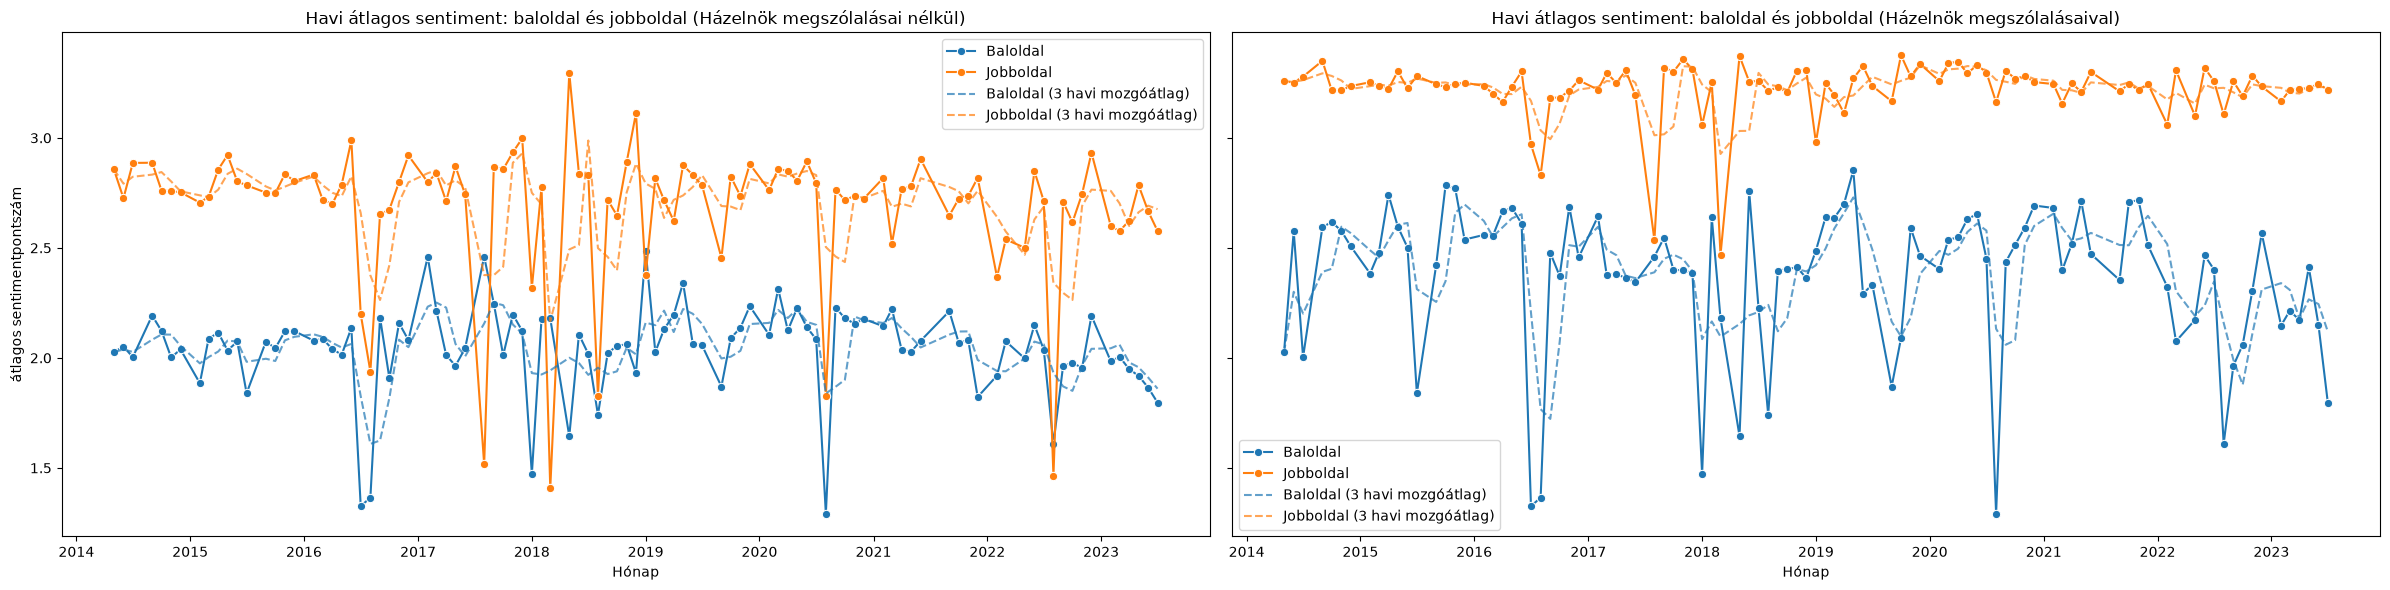

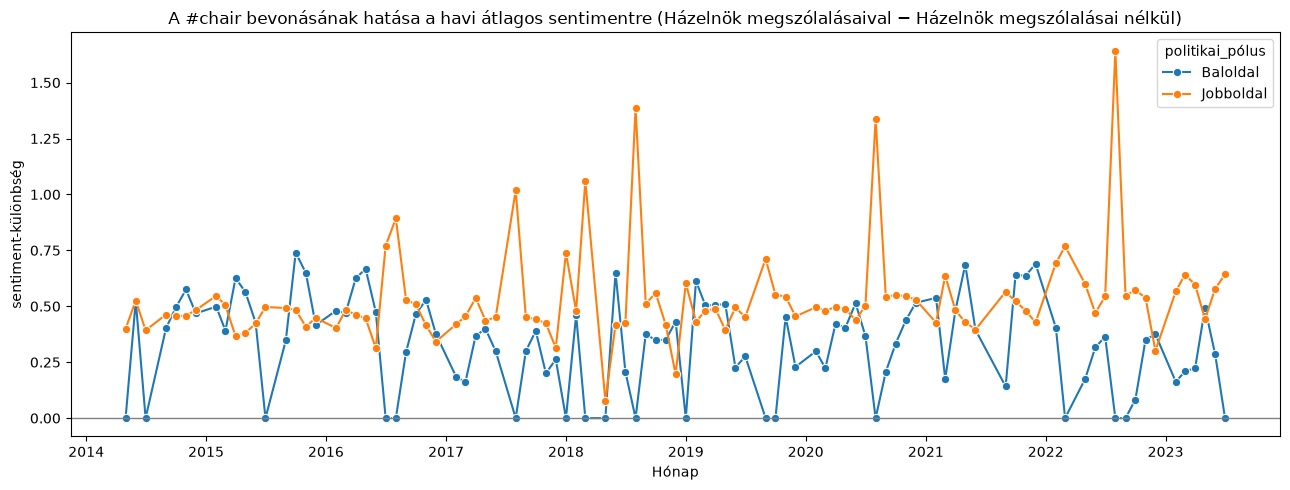

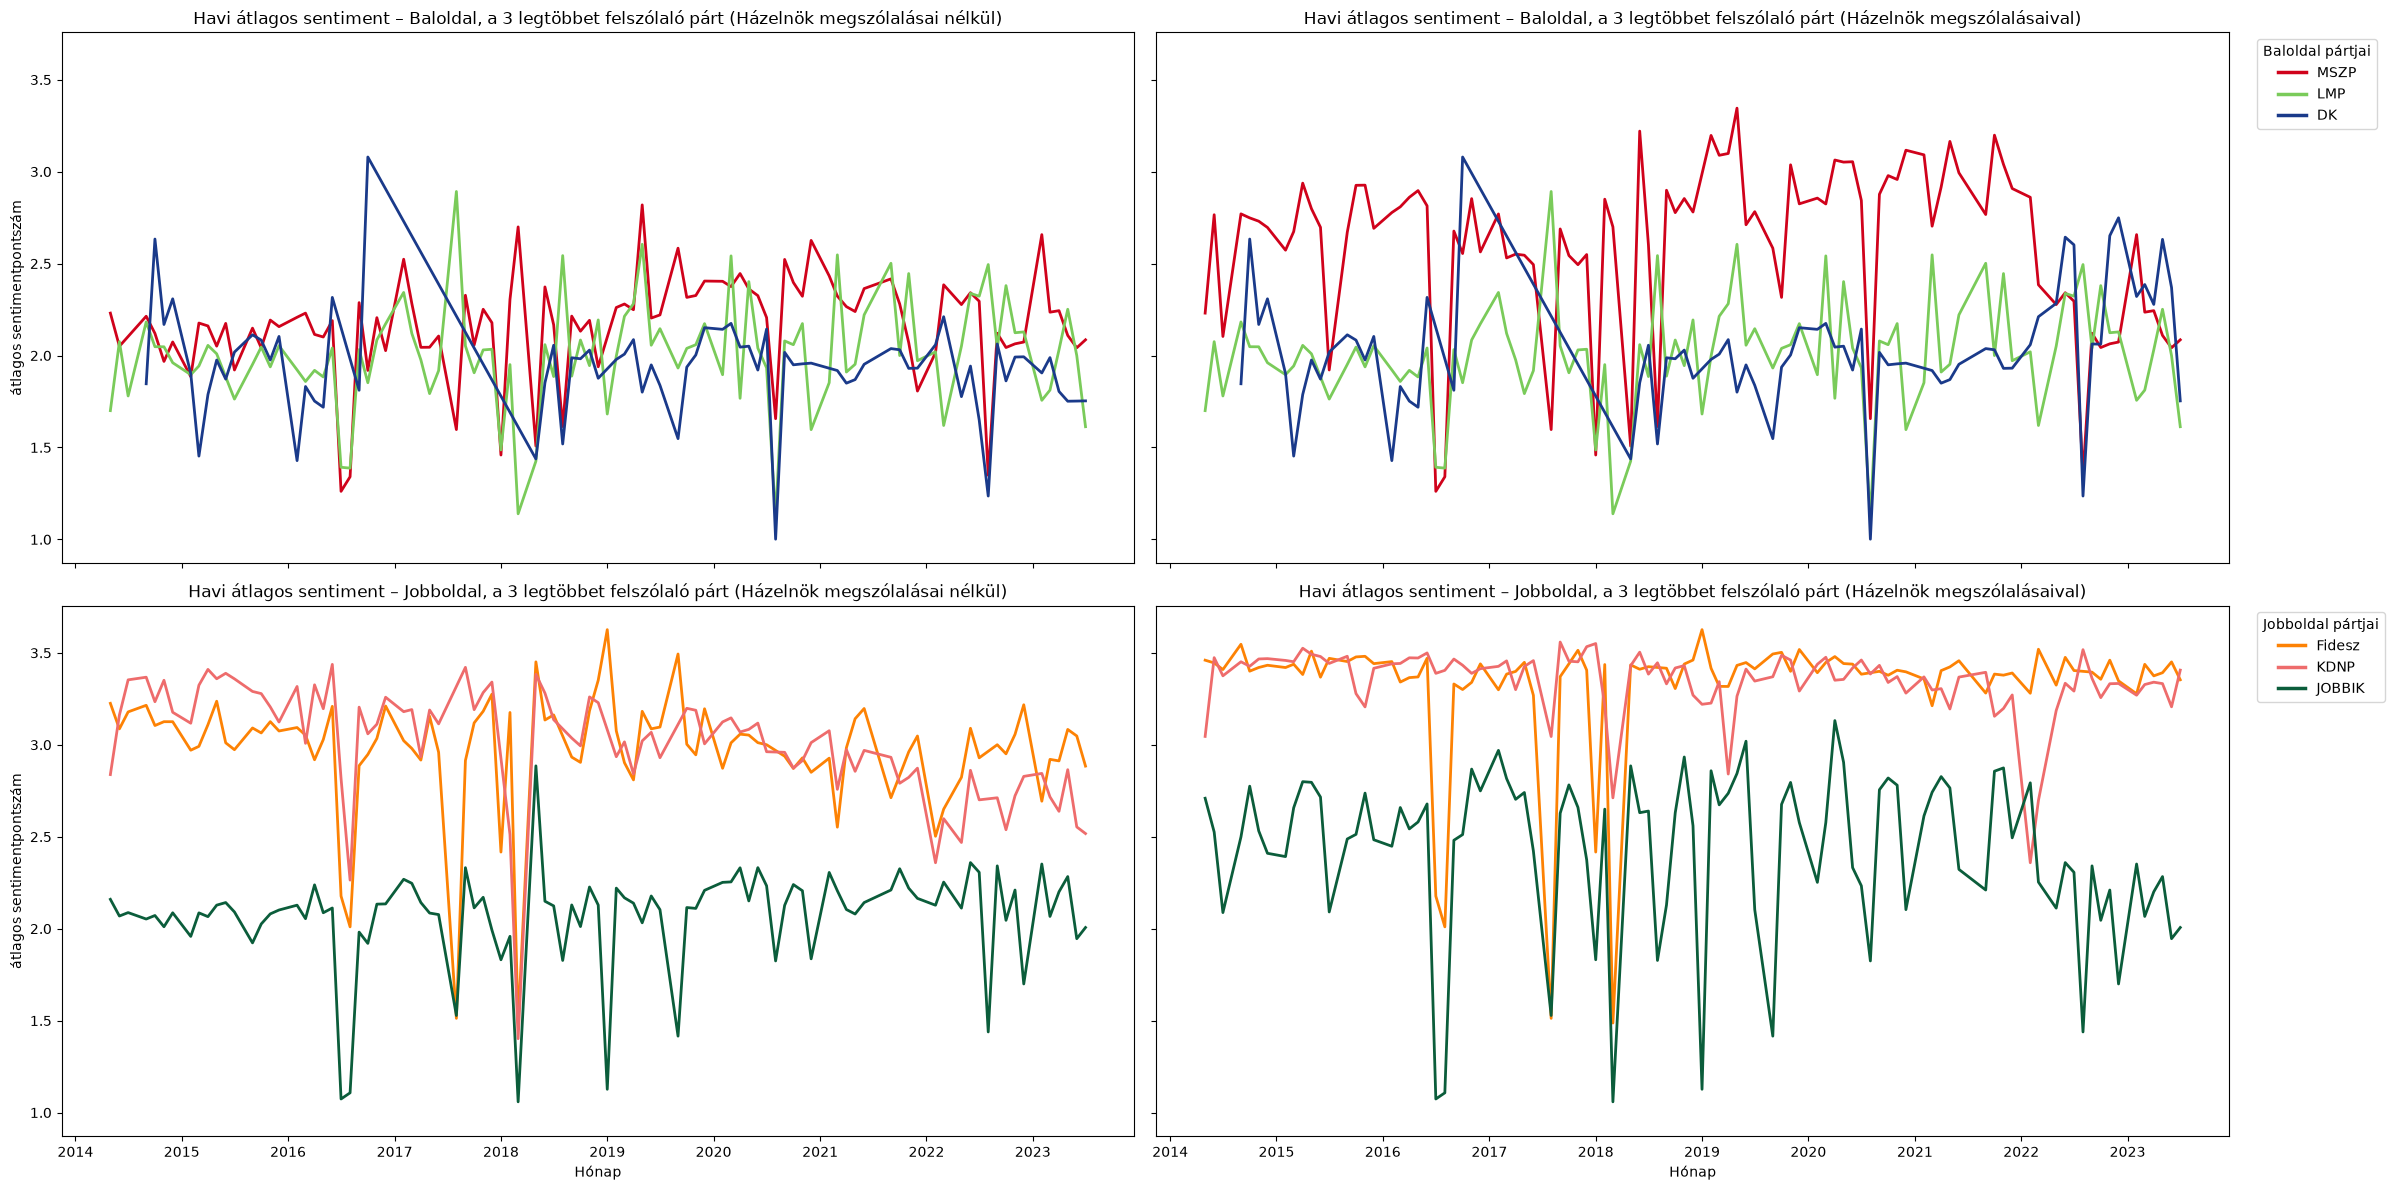

In [ ]:
# A két vizsgált politikai pólus és a színük az ábrákon.
POLUSOK = ["Baloldal", "Jobboldal"]
polus_szinek = dict(zip(POLUSOK, sns.color_palette(n_colors=len(POLUSOK))))


# Havi átlagos sentiment pólusonként (baloldal / jobboldal).
def havi_polus_atlag(adat):
    return (
        adat[adat["politikai_pólus"].isin(POLUSOK)]
        .groupby(["hónap", "politikai_pólus"], as_index=False)["sentiment"]
        .mean()
    )


# ----------------Bal és jobboldal havi átlagos szentimentjének összevetése------------------
fig, tengelyek = plt.subplots(1, len(DATASETEK), figsize=(24, 6), sharey=True)
# Egy panel adathalmazonként: havi átlag (pontokkal) és 3 havi mozgóátlag (szaggatott vonal).
for tengely, (cimke, adat) in zip(tengelyek, DATASETEK.items()):
    havi = havi_polus_atlag(adat)
    sns.lineplot(
        data=havi,
        x="hónap",
        y="sentiment",
        hue="politikai_pólus",
        hue_order=POLUSOK,
        palette=polus_szinek,
        marker="o",
        ax=tengely,
    )
    for oldal, reszhalmaz in havi.groupby("politikai_pólus"):
        # 3 hónapos mozgóátlag: az egymást követő 3 hónap átlaga, ami kisimítja a havi ingadozást.
        simitott = (
            reszhalmaz.sort_values("hónap")
            .set_index("hónap")["sentiment"]
            .rolling(3, min_periods=1)
            .mean()
        )
        tengely.plot(
            simitott.index,
            simitott,
            linestyle="--",
            color=polus_szinek[oldal],
            alpha=0.7,
            label=f"{oldal} (3 havi mozgóátlag)",
        )
    tengely.set_title(f"Havi átlagos sentiment: baloldal és jobboldal ({cimke})")
    tengely.set_xlabel("Hónap")
    tengely.set_ylabel("átlagos sentimentpontszám")
    tengely.legend()
plt.tight_layout()
plt.show()

# --------------------A házelnöki hatás mértéke-------------------------------
# A két adathalmaz havi átlagait összefésüljük és kivonjuk egymásból, ezzel szemléltetve a két adathalmaz közötti eltérést
kulonbseg = (
    havi_polus_atlag(adatkeret_teljes)
    .merge(
        havi_polus_atlag(adatkeret),
        on=["hónap", "politikai_pólus"],
        suffixes=("_teljes", "_szurt"),
        how="outer",
    )
    .assign(kulonbseg=lambda t: t["sentiment_teljes"] - t["sentiment_szurt"])
)
plt.figure(figsize=(13, 5))
sns.lineplot(
    data=kulonbseg,
    x="hónap",
    y="kulonbseg",
    hue="politikai_pólus",
    hue_order=POLUSOK,
    palette=polus_szinek,
    marker="o",
)
plt.axhline(0, color="grey", linewidth=1)
plt.title(
    f"A #chair bevonásának hatása a havi átlagos sentimentre ({CIMKE_TELJES} − {CIMKE_SZURT})"
)
plt.xlabel("Hónap")
plt.ylabel("sentiment-különbség")
plt.tight_layout()
plt.show()

# A 3 legtöbbet felszólaló pártok havi átlagos sentimentje, pártonként

# a top x párt amit látni szeretnénk
LEGTOBB_PART_POLUSONKENT = 3
# szín kódolás
PART_SZINEK = {
    "Fidesz": "#FD8204",  # narancssárga
    "KDNP": "#EE6C6C",  # világosabb piros
    "JOBBIK": "#0B5D3B",  # sötétzöld
    "MSZP": "#D0021B",  # vörös
    "DK": "#1A3A8A",  # sötétkék
    "LMP": "#7ACB5A",  # világoszöld
}
# Az ábra sorai: baloldal és jobboldal
# a közép/egyéb pártokat kevés felszólalásuk miatt nem jelenítettük meg
POLUS_SORREND = [p for p in POLUSOK if p in set(adatkeret_teljes["politikai_pólus"])]
fig, tengelyek = plt.subplots(
    len(POLUS_SORREND),
    len(DATASETEK),
    figsize=(24, 6 * len(POLUS_SORREND)),
    sharex=True,
    sharey=True,
    squeeze=False,
)

for sor, polus in zip(tengelyek, POLUS_SORREND):
    # az x legtöbbet felszólaló párt
    legjelentosebb_partok = (
        adatkeret_teljes.loc[adatkeret_teljes["politikai_pólus"] == polus, "párt"]
        .value_counts()
        .head(LEGTOBB_PART_POLUSONKENT)
        .index.tolist()
    )
    part_szinek = {
        part: PART_SZINEK.get(part, "#7F7F7F") for part in legjelentosebb_partok
    }
    for tengely, (cimke, adat) in zip(sor, DATASETEK.items()):
        reszadat = adat[adat["párt"].isin(legjelentosebb_partok)]
        if not reszadat.empty:
            sns.lineplot(
                data=reszadat,
                x="hónap",
                y="sentiment",
                hue="párt",
                hue_order=legjelentosebb_partok,
                palette=part_szinek,
                estimator="mean",
                errorbar=None,
                linewidth=2,
                legend=False,
                ax=tengely,
            )
        tengely.set_title(
            f"Havi átlagos sentiment – {polus}, a {LEGTOBB_PART_POLUSONKENT} legtöbbet felszólaló párt ({cimke})"
        )
        tengely.set_xlabel("Hónap")
        tengely.set_ylabel("átlagos sentimentpontszám")
    # Jelmagyarázat
    sor[-1].legend(
        handles=[
            plt.Line2D([], [], color=szin, linewidth=2.5, label=part)
            for part, szin in part_szinek.items()
        ],
        title=f"{polus} pártjai",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
plt.tight_layout()
plt.show()

### 2.3 Bal- és jobboldal, illetve a pártok közötti különbségek

Ez a szakasz felel a **K1 bal–jobb részére**: Welch-féle t-próba a bal- és jobboldal között, egyutas ANOVA a pártok között, valamint pólusonkénti és pártonkénti variancia (frakciófegyelem).

===== Házelnök megszólalásai nélkül =====
Welch-féle t-próba (jobb − bal): t = 87.2143, p = < 1e-300
Hatásméret (Hedges g, jobb − bal): g = 0.785
Egyutas ANOVA: F = 1267.9206, p = < 1e-300
Pólusonkénti sentiment-variancia:


,count,mean,var
politikai_pólus,,,
Baloldal,17007,2.0810,0.6841
Jobboldal,34933,2.7819,0.8514


Pártonkénti sentiment-variancia:


,count,mean,var
párt,,,
MNOÖ,162,3.2408,0.3118
EGYÜTT,83,2.1043,0.3933
MLP,79,2.1303,0.5593
Mi Hazánk,551,1.9381,0.5723
DK,2838,1.9519,0.6194
Szolidaritás,32,2.0971,0.6447
JOBBIK,9105,2.1267,0.6501
LMP,4554,2.0215,0.6635
Fidesz,17584,3.0376,0.6752


Legegységesebb párt: MNOÖ
Legheterogénebb párt: Párbeszéd

===== Házelnök megszólalásaival =====
Welch-féle t-próba (jobb − bal): t = 105.8444, p = < 1e-300
Hatásméret (Hedges g, jobb − bal): g = 0.874
Egyutas ANOVA: F = 2518.6714, p = < 1e-300
Pólusonkénti sentiment-variancia:


,count,mean,var
politikai_pólus,,,
Baloldal,24470,2.5234,0.9875
Jobboldal,83143,3.2550,0.6173


... (2 outputs left out)

Legegységesebb párt: MNOÖ
Legheterogénebb párt: MSZP

Pólusonkénti összevetés (különbség = Házelnök megszólalásaival − Házelnök megszólalásai nélkül):


Házelnök megszólalásai nélkül                  \
                                        count    mean     var   
politikai_pólus                                                 
Baloldal                                17007  2.0810  0.6841   
Jobboldal                               34933  2.7819  0.8514   

                Házelnök megszólalásaival                 különbség          
                                    count    mean     var      mean     var  
politikai_pólus                                                              
Baloldal                            24470  2.5234  0.9875    0.4424  0.3035  
Jobboldal                           83143  3.2550  0.6173    0.4731 -0.2341

Pártonkénti összevetés (különbség = Házelnök megszólalásaival − Házelnök megszólalásai nélkül):


Házelnök megszólalásai nélkül                  \
                                     count    mean     var   
párt                                                         
MNOÖ                                   162  3.2408  0.3118   
EGYÜTT                                  83  2.1043  0.3933   
MLP                                     79  2.1303  0.5593   
Mi Hazánk                              551  1.9381  0.5723   
DK                                    2838  1.9519  0.6194   
Szolidaritás                            32  2.0971  0.6447   
JOBBIK                                9105  2.1267  0.6501   
LMP                                   4554  2.0215  0.6635   
Fidesz                               17584  3.0376  0.6752   
MSZP                                  8208  2.1802  0.6797   
Momentum                               308  1.9595  0.6892   
ÚK                                     169  2.3803  0.7030   
KDNP                                  7275  3.0544  0.7332   
Volner                                   8  2.2985  0.7856   
Párbeszéd                             1375  1.9514  0.7929   

             Házelnök megszólalásaival                 különbség          
                                 count    mean     var      mean     var  
párt                                                                      
MNOÖ                               162  3.2408  0.3118    0.0000  0.0000  
EGYÜTT                              83  2.1043  0.3933    0.0000  0.0000  
MLP                                 79  2.1303  0.5593    0.0000  0.0000  
Mi Hazánk                         1130  2.6397  0.7830    0.7015  0.2107  
DK                                3253  2.1608  0.8537    0.2090  0.2343  
Szolidaritás                        32  2.0971  0.6447    0.0000  0.0000  
JOBBIK                           15338  2.6688  0.8899    0.5420  0.2399  
LMP                               4554  2.0215  0.6635    0.0000  0.0000  
Fidesz                           45071  3.4127  0.4478    0.3751 -0.2273  
MSZP                             15256  2.8030  0.9200    0.6227  0.2403  
Momentum                           308  1.9595  0.6892    0.0000  0.0000  
ÚK                                 169  2.3803  0.7030    0.0000  0.0000  
KDNP                             21186  3.3885  0.4228    0.3341 -0.3103  
Volner                               8  2.2985  0.7856    0.0000  0.0000  
Párbeszéd                         1375  1.9514  0.7929    0.0000  0.0000

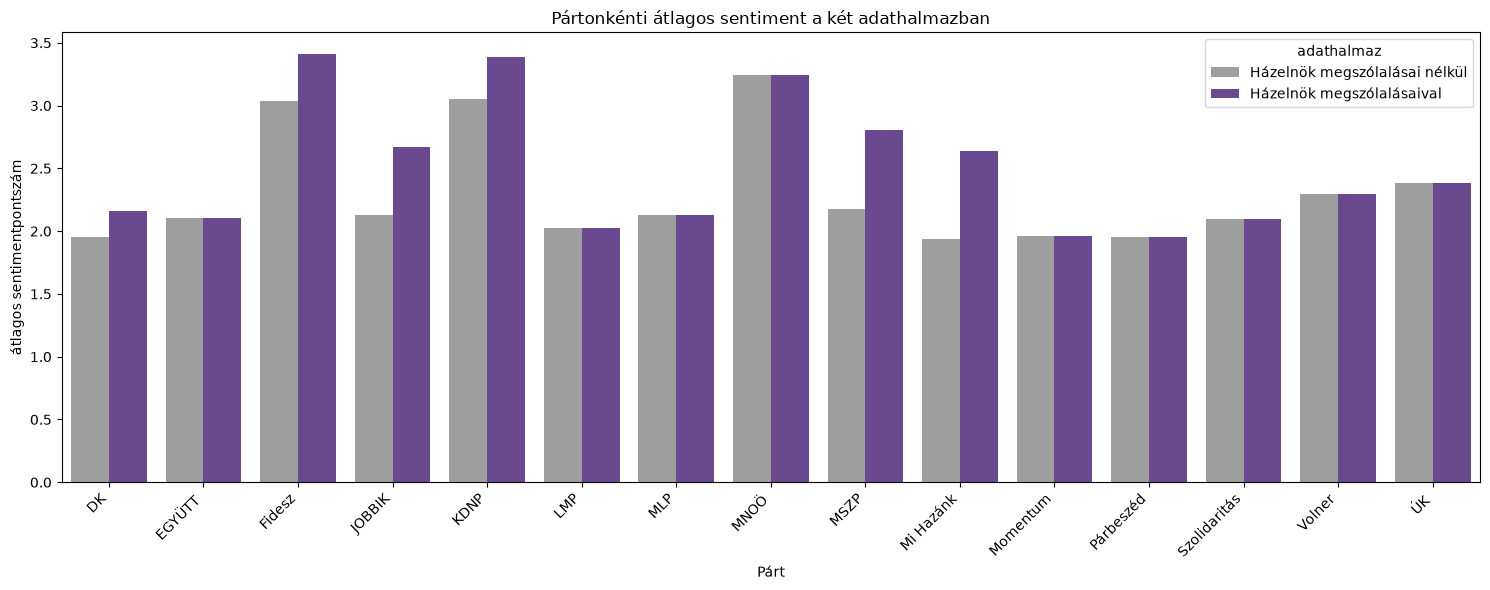

In [ ]:
# Szignifikanciatesztek és frakciófegyelem, mindkét adathalmazon
# A nagyon kicsi p-értékeket olvashatóan írja ki (a 0 helyett „< 1e-300”).
def formazott_p(p_ertek):
    return "< 1e-300" if p_ertek == 0 else f"{p_ertek:.3e}"


# Hatásméret (Hedges g): a két csoport különbsége a szóráshoz képest
# (0,2 -> kicsi, 0,5 -> közepes, 0,8 -> nagy).
def hedges_g(a, b):
    """Standardizált átlagkülönbség kis mintás korrekcióval (a − b)."""
    na, nb = len(a), len(b)
    egyesitett = np.sqrt(
        ((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2)
    )
    return (a.mean() - b.mean()) / egyesitett * (1 - 3 / (4 * (na + nb) - 9))


# Két csoport összevetése (a − b): Welch-féle t-próba, kérésre Mann–Whitney-próba, és hatásméret.
# Az irányosság: "greater" (a > b), "less" (a < b) vagy "two-sided" (kétoldalú). A felszólalásokat függetlennek tekintjük.
def csoportok_osszevetese(a, b, iranyossag="two-sided", mann_whitney=True):
    irany = "kétoldalú" if iranyossag == "two-sided" else "egyoldalú"
    welch = stats.ttest_ind(a, b, equal_var=False, alternative=iranyossag)
    eredmeny = {
        "különbség": a.mean() - b.mean(),
        "t": welch.statistic,
        f"p (Welch, {irany})": welch.pvalue,
    }
    if mann_whitney:
        mw = stats.mannwhitneyu(a, b, alternative=iranyossag)
        eredmeny[f"p (Mann–Whitney, {irany})"] = mw.pvalue
    eredmeny["Hedges g"] = hedges_g(a, b)
    if mann_whitney:
        eredmeny["rang-biszeriális r"] = 2 * mw.statistic / (len(a) * len(b)) - 1
    return eredmeny


# Egy adathalmazra lefuttatja a t-próbát és az ANOVA-t, és kiírja a varianciatáblákat.
def szignifikancia_elemzes(adat, cimke):

    print(f"===== {cimke} =====")
    baloldali_sentiment = adat.loc[
        adat["politikai_pólus"] == "Baloldal", "sentiment"
    ].dropna()
    jobboldali_sentiment = adat.loc[
        adat["politikai_pólus"] == "Jobboldal", "sentiment"
    ].dropna()

    # Welch-féle t-próba: különbözik-e a bal- és a jobboldal átlagos sentimentje? (p < 0,05 esetén szignifikáns a különbség)
    # A hatásméret azt mutatja meg, mekkora a különbség a szóráshoz képest (a p-érték csak azt, hogy van-e).
    teszt = csoportok_osszevetese(
        jobboldali_sentiment, baloldali_sentiment, mann_whitney=False
    )
    print(
        f"Welch-féle t-próba (jobb − bal): t = {teszt['t']:.4f}, p = {formazott_p(teszt['p (Welch, kétoldalú)'])}"
    )
    print(f"Hatásméret (Hedges g, jobb − bal): g = {teszt['Hedges g']:.3f}")

    # Egyutas ANOVA: van-e különbség a pártok átlagai között (a t-próba kettőnél több csoportra általánosítva).
    partcsoportok = [
        csoport["sentiment"].dropna() for _, csoport in adat.groupby("párt")
    ]
    anova = stats.f_oneway(*partcsoportok)
    print(f"Egyutas ANOVA: F = {anova.statistic:.4f}, p = {formazott_p(anova.pvalue)}")

    # Variancia: mennyire szóródnak az értékek az átlag körül. Kicsi variancia egységes frakciót, nagy változatosat jelent.
    polus_variancia = (
        adat[adat["politikai_pólus"].isin(["Baloldal", "Jobboldal"])]
        .groupby("politikai_pólus")["sentiment"]
        .agg(["count", "mean", "var"])
        .sort_index()
    )
    print("Pólusonkénti sentiment-variancia:")
    display(polus_variancia.round(4))

    part_variancia = (
        adat.groupby("párt")["sentiment"]
        .agg(["count", "mean", "var"])
        .sort_values("var")
    )
    print("Pártonkénti sentiment-variancia:")
    display(part_variancia.round(4))
    print(f"Legegységesebb párt: {part_variancia['var'].idxmin()}")
    print(f"Legheterogénebb párt: {part_variancia['var'].idxmax()}\n")
    return polus_variancia, part_variancia


# Elemzés az adathalmazokon
szig_eredmenyek = {
    cimke: szignifikancia_elemzes(adat, cimke) for cimke, adat in DATASETEK.items()
}


# A két adathalmaz tábláját egymás mellé teszi, és kiszámolja a különbségüket.
def osszevetes(tablak):
    tabla = pd.concat(tablak, axis=1)
    for mutato in ("mean", "var"):
        tabla[("különbség", mutato)] = (
            tabla[(CIMKE_TELJES, mutato)] - tabla[(CIMKE_SZURT, mutato)]
        )
    return tabla.round(4)


print(f"Pólusonkénti összevetés (különbség = {CIMKE_TELJES} − {CIMKE_SZURT}):")
display(osszevetes({cimke: e[0] for cimke, e in szig_eredmenyek.items()}))
print(f"Pártonkénti összevetés (különbség = {CIMKE_TELJES} − {CIMKE_SZURT}):")
display(osszevetes({cimke: e[1] for cimke, e in szig_eredmenyek.items()}))

# Pártonkénti átlagos sentiment a két adathalmazban

ADATHALMAZ_SZINEK = {CIMKE_SZURT: "#9E9E9E", CIMKE_TELJES: "#6A3D9A"}
# Diagram
atlagok = (
    pd.concat([adat.assign(adathalmaz=cimke) for cimke, adat in DATASETEK.items()])
    .groupby(["párt", "adathalmaz"], as_index=False)["sentiment"]
    .mean()
)
plt.figure(figsize=(15, 6))
sns.barplot(
    data=atlagok,
    x="párt",
    y="sentiment",
    hue="adathalmaz",
    hue_order=list(DATASETEK),
    palette=ADATHALMAZ_SZINEK,
    order=sorted(atlagok["párt"].unique()),
)
plt.title("Pártonkénti átlagos sentiment a két adathalmazban")
plt.xlabel("Párt")
plt.ylabel("átlagos sentimentpontszám")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Tehát azt találtuk, hogy a különbségek szignifikánsak a jobboldali pártok  és a baloldali pártok kommunikációjában

**Az eredmények röviden** (a teljes korpuszon futtatva; az átlag a felszólalások sentimentpontszámának átlaga):

| Adathalmaz | Baloldal | Jobboldal | Különbség | Welch t | Hatásméret (Hedges g) |
|---|---|---|---|---|---|
| Házelnök megszólalásai nélkül | 2,081 (n = 17 007) | 2,782 (n = 34 933) | 0,70 | 87,2 | 0,79 |
| Házelnök megszólalásaival | 2,523 (n = 24 470) | 3,255 (n = 83 143) | 0,73 | 105,8 | 0,87 |

- **Bal–jobb:** mindkét adathalmazon a jobboldali pártok felszólalásai szignifikánsan pozitívabbak (p < 1e-300), és a hatásméret nagy (g ≈ 0,8–0,9). A t értéke pozitív, mert a próba a jobboldali átlagból vonja ki a baloldalit (jobb − bal).
- **Pártok között:** az egyutas ANOVA szerint a pártok átlagai is szignifikánsan eltérnek (F = 1 268, illetve 2 519; p < 1e-300).
- **Az elnöki felszólalások hatása:** bevonásukkal mindkét oldal átlaga kb. 0,44–0,47 ponttal nő, a két oldal különbsége alig változik (0,70 → 0,73).
- **Egységesség (variancia):** a variancia iránya a házelnöki felszólalásoktól függ. Nélkülük a jobboldal varianciája nagyobb (0,85 a 0,68-cal szemben), velük a baloldalé (0,99 a 0,62-vel szemben). A legegységesebb párt mindkét esetben az MNOÖ (0,31), a legheterogénebb a Párbeszéd (0,79), illetve az MSZP (0,92). Kis elemszámú pártoknál (pl. Volner, n = 8) a rangsor nem megbízható.

**Értelmezés:** a jobboldal pozitívabb, de ez főként a kormányzati szerepből adódhat, nem a politikai irányultságból. A jobboldali felszólalások 71%-a (házelnök nélkül) a kormánypártoké (Fidesz, KDNP). A jobboldali ellenzéki pártok (Jobbik, Mi Hazánk stb.) átlaga (2,12) szinte megegyezik a baloldaliakéval (2,08), míg a kormánypártoké 3,04 (a pártonkénti átlagok táblázatából számolva). A bal–jobb különbség tehát lényegében a 3. fejezetben vizsgált kormánypárt–ellenzék különbséget tükrözi. A próbák a felszólalásokat egymástól függetlennek tekintik (ez egyszerűsítő feltevés). A nagy elemszám miatt a p-érték eleve nagyon kicsi, ezért az eltérés nagyságáról a hatásméret ad érdemi képet.

## 3. Hipotézisvizsgálat: kormánypártok és ellenzék (H1, H2)

- **H1:** A kormánypártok (Fidesz, KDNP) felszólalásainak átlagos sentimentje szignifikánsan magasabb, mint az ellenzéki pártoké.
- **H2:** Az ellenzéki pártok sentimentje időben nagyobb ingadozást mutat, mint a kormánypártoké.

**Besorolás:** a vizsgált időszakban végig a Fidesz–KDNP volt kormányon, így ők a *kormánypártok*, minden más párt az *ellenzék*. A nemzetiségi szószólót (MNOÖ) egyik csoportba sem soroljuk, és kihagyjuk. A besorolás a következő cellában a `KORMANYPARTOK` és a `NEM_BESOROLT` halmazzal módosítható.

Minden elemzés mindkét adathalmazon (#chair nélkül és #chair-rel) lefut. A szignifikanciaszint `ALFA = 0.05`, és mivel mindkét hipotézis irányt állít, egyoldalú próbákat használunk.

In [ ]:
# --------------------------- Hipotézisvizsgálat előkészítése
# (ALFA = 0,05: akkor tekintünk egy különbséget szignifikánsnak, ha annak véletlen előfordulási esélye 5% alatti).
KORMANYPARTOK = {"Fidesz", "KDNP"}
NEM_BESOROLT = {"MNOO"}
ALFA = 0.05
BLOKKOK = ["Kormánypártok", "Ellenzék"]
blokk_szinek = {"Kormánypártok": "#E8833A", "Ellenzék": "#3A6EA5"}


#  kormánypárt, ellenzék, vagy kimarad
def blokk_besorolas(part_azonosito):
    if part_azonosito in KORMANYPARTOK:
        return "Kormánypártok"
    if part_azonosito in NEM_BESOROLT:
        return None
    return "Ellenzék"


# mindkét adatkeretet kiegészítjük a kormány/ellenzék címkével és az évvel és a besorolatlan pártok kimaradnak
BLOKK_DATASETEK = {
    cimke: adat.assign(blokk=adat["párt_azonosító"].map(blokk_besorolas))
    .dropna(subset=["blokk"])
    .assign(év=lambda t: t["dátum"].dt.year)
    for cimke, adat in DATASETEK.items()
}

print("Pártok besorolása és felszólalásszáma a két adathalmazban:")
# Kiírjuk, hogy melyik párt melyik csoportba került és mennyiszer szólalt fel  -> ellenőrzés
besorolas = (
    adatkeret_teljes.groupby("párt")["párt_azonosító"]
    .first()
    .map(blokk_besorolas)
    .fillna("kihagyva")
)
display(
    pd.DataFrame(
        {cimke: adat.groupby("párt").size() for cimke, adat in DATASETEK.items()}
    )
    .fillna(0)
    .astype(int)
    .assign(blokk=besorolas)
    .sort_values(["blokk", CIMKE_TELJES], ascending=[False, False])
)

Pártok besorolása és felszólalásszáma a két adathalmazban:


,Házelnök megszólalásai nélkül,Házelnök megszólalásaival,blokk
párt,,,
MNOÖ,162,162,kihagyva
Fidesz,17584,45071,Kormánypártok
KDNP,7275,21186,Kormánypártok
JOBBIK,9105,15338,Ellenzék
MSZP,8208,15256,Ellenzék
LMP,4554,4554,Ellenzék
DK,2838,3253,Ellenzék
Párbeszéd,1375,1375,Ellenzék
Mi Hazánk,551,1130,Ellenzék


### 3.1 H1: magasabb-e a kormánypártok átlagos sentimentje?

**Feltevés:** a felszólalásokat egymástól függetlennek tekintjük, ezért minden felszólalás külön megfigyelés. (Valójában ugyanaz a képviselő sokszor szólal fel, és az ülésnap napirendje is hat a felszólalásokra, ezért a p-értékek valószínűleg a valósnál kisebbek. A hatásméret becslése erre kevésbé érzékeny.)

**Próbák** (egyoldalúak: kormány > ellenzék):
- **Welch-féle t-próba** az átlagok különbségére,
- **Mann–Whitney U-próba**, amely nem feltételezi az értékek normális eloszlását.

**Hatásméret:** Hedges-féle *g* és rang-biszeriális *r*.

Ezután évenként is megnézzük, hogy a különbség a teljes időszakban fennáll-e.

===== H1 – Házelnök megszólalásai nélkül =====
Leíró statisztika:


,n,átlag,medián,szórás,CI95_alsó,CI95_felső
blokk,,,,,,
Kormánypártok,24859,3.0425,3.1246,0.8320,3.0322,3.0529
Ellenzék,27310,2.0941,1.9200,0.8191,2.0844,2.1038


Hipotézisteszt (egyoldalú: kormány > ellenzék):


,n kormány,n ellenzék,átlag kormány,átlag ellenzék,különbség,t,"p (Welch, egyoldalú)","p (Mann–Whitney, egyoldalú)",Hedges g,rang-biszeriális r
felszólalás,24859,27310,3.0425,2.0941,0.9485,131.0091,< 1e-300,< 1e-300,1.1493,0.5969


Évenkénti bontás:


,n kormány,n ellenzék,átlag kormány,átlag ellenzék,különbség,t,"p (Welch, egyoldalú)",Hedges g,szignifikáns (p < 0.05)
év,,,,,,,,,
2014,1619,2404,3.1512,2.0602,1.0909,45.4576,< 1e-300,1.4633,True
2015,3679,4606,3.1325,2.0687,1.0638,63.4463,< 1e-300,1.4092,True
2016,3262,3648,3.0668,2.0793,0.9874,51.8325,< 1e-300,1.2470,True
2017,3124,3062,3.1033,2.1195,0.9838,45.9804,< 1e-300,1.1696,True
2018,2158,2503,3.1031,2.0844,1.0186,41.7825,< 1e-300,1.2282,True
2019,2260,2528,3.0306,2.1375,0.8932,35.6982,4.096e-247,1.0372,True
2020,3298,3206,2.9884,2.1946,0.7938,36.6407,1.585e-267,0.9093,True
2021,2411,2124,2.9386,2.1145,0.8241,31.4528,1.106e-196,0.9347,True
2022,1739,1838,2.8976,2.0652,0.8324,29.0259,9.960e-167,0.9713,True


... (2 outputs left out)

Hipotézisteszt (egyoldalú: kormány > ellenzék):


,n kormány,n ellenzék,átlag kormány,átlag ellenzék,különbség,t,"p (Welch, egyoldalú)","p (Mann–Whitney, egyoldalú)",Hedges g,rang-biszeriális r
felszólalás,66257,41585,3.405,2.5738,0.8312,153.1245,< 1e-300,< 1e-300,1.042,0.499


Évenkénti bontás:


,n kormány,n ellenzék,átlag kormány,átlag ellenzék,különbség,t,"p (Welch, egyoldalú)",Hedges g,szignifikáns (p < 0.05)
év,,,,,,,,,
2014,4819,3686,3.4430,2.5446,0.8984,51.0245,< 1e-300,1.1805,True
2015,9624,7896,3.4440,2.6272,0.8169,67.8425,< 1e-300,1.0696,True
2016,8121,6086,3.3944,2.6129,0.7815,55.7789,< 1e-300,0.9981,True
2017,8356,4336,3.4231,2.5436,0.8795,51.8427,< 1e-300,1.1025,True
2018,5800,3587,3.4004,2.5530,0.8473,44.6041,< 1e-300,1.0478,True
2019,6077,3701,3.4063,2.6008,0.8055,42.9985,< 1e-300,0.9769,True
2020,8998,4671,3.4117,2.6323,0.7794,47.3039,< 1e-300,0.9654,True
2021,5992,3366,3.3437,2.6418,0.7019,35.6123,8.546e-250,0.8386,True
2022,4780,2380,3.3735,2.3763,0.9972,45.0416,< 1e-300,1.2435,True


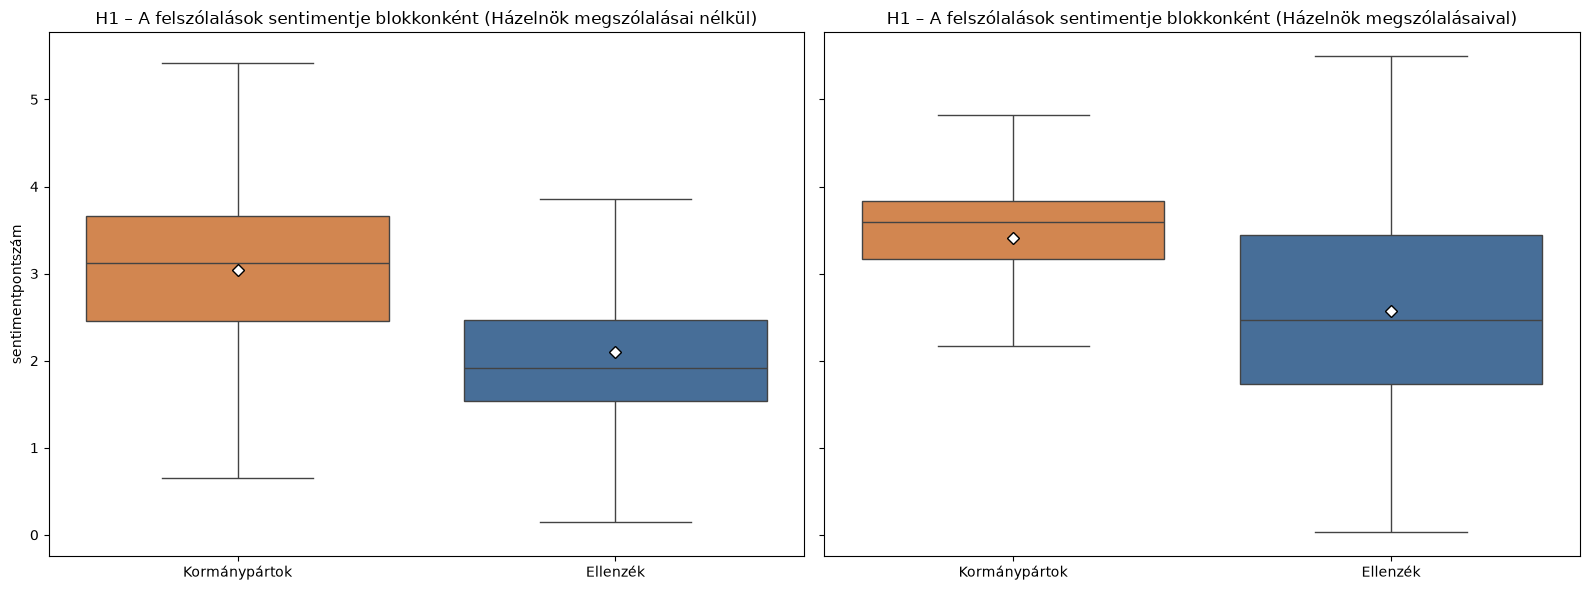

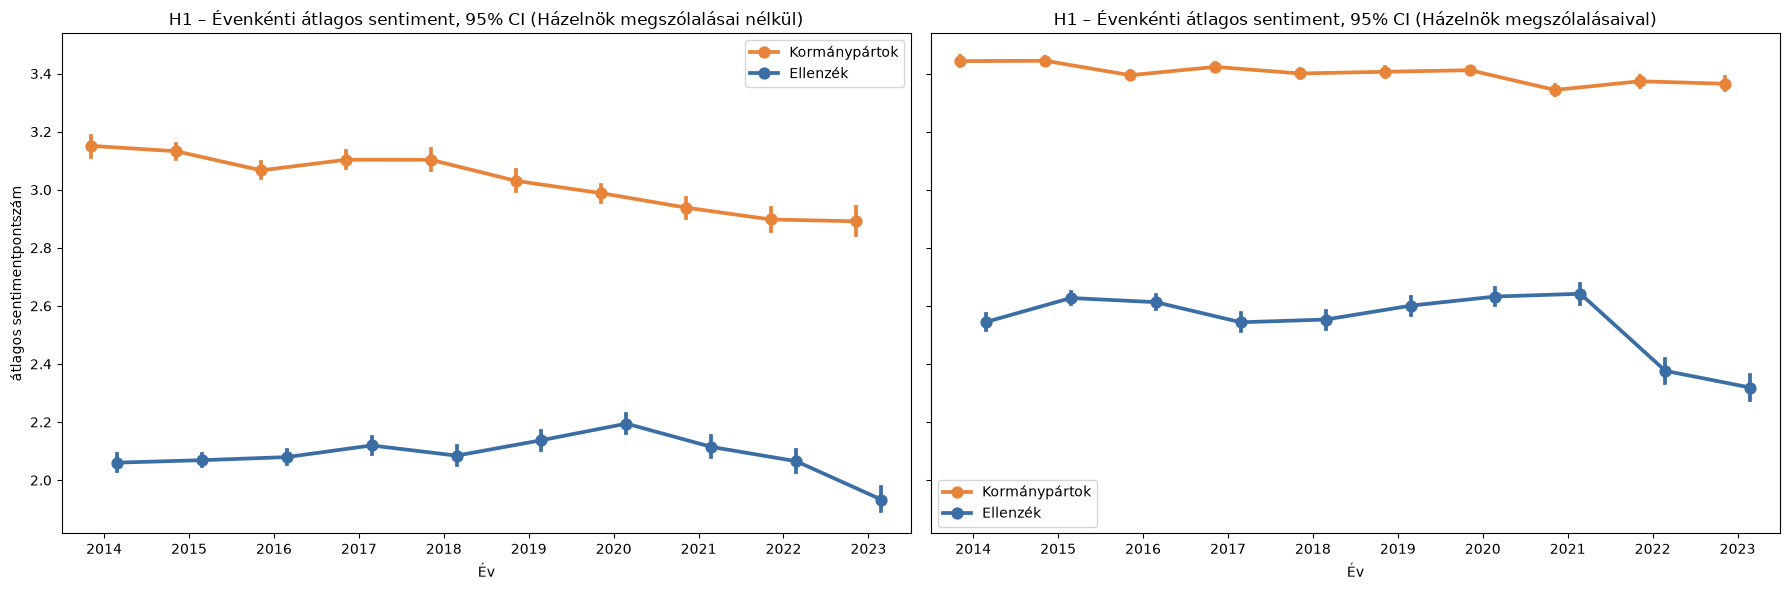

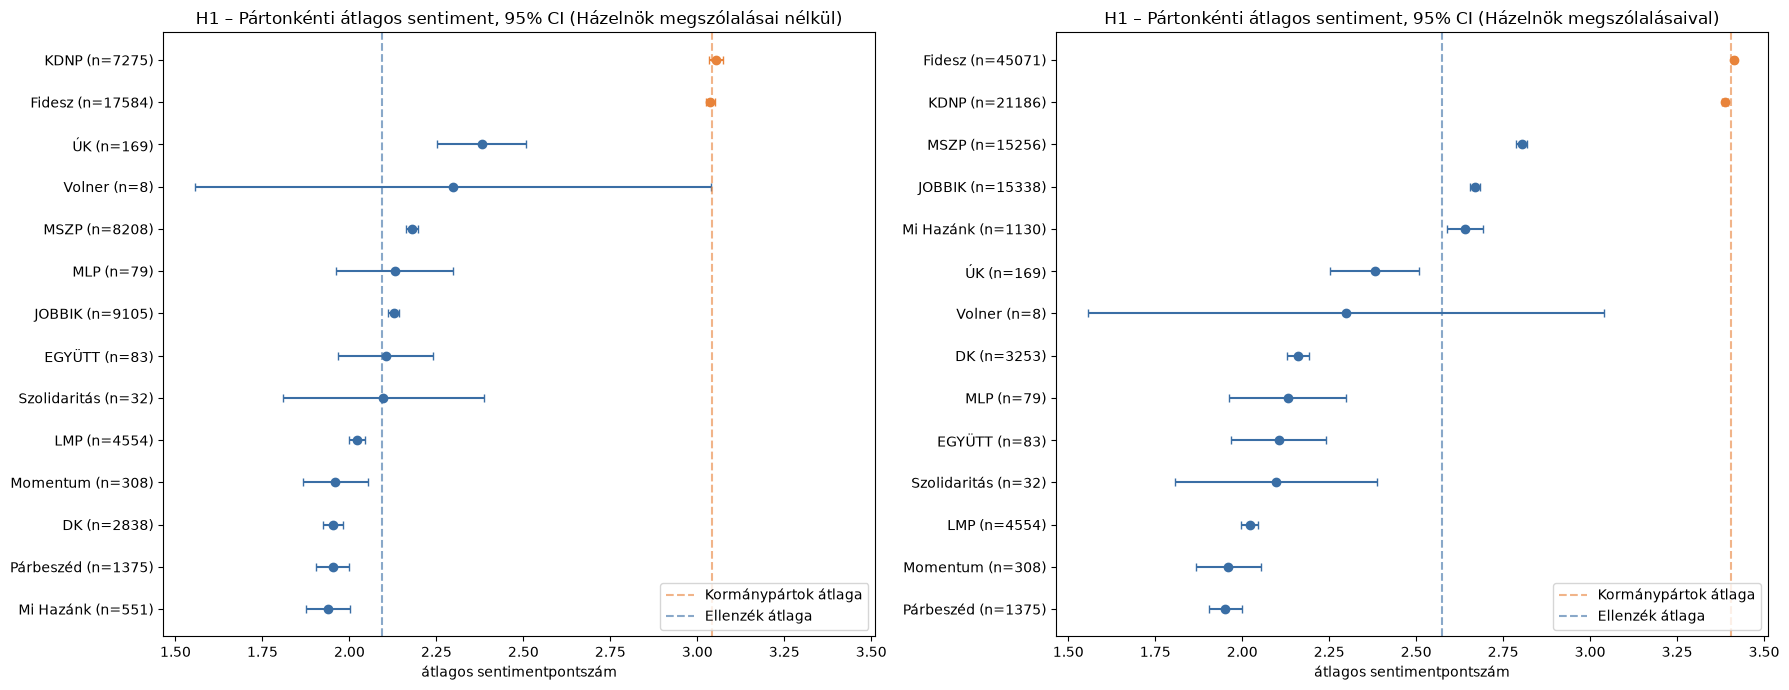

In [ ]:
# H1: kormánypártok vs. ellenzék átlagos sentimentje
def leiro_statisztika(adat, csoport):

    tabla = adat.groupby(csoport)["sentiment"].agg(
        n="size", átlag="mean", medián="median", szórás="std"
    )
    hiba = tabla["szórás"] / np.sqrt(tabla["n"])
    t_krit = stats.t.ppf(0.975, (tabla["n"] - 1).clip(lower=1))
    tabla["CI95_alsó"] = tabla["átlag"] - t_krit * hiba
    tabla["CI95_felső"] = tabla["átlag"] + t_krit * hiba
    return tabla


# Kormánypárti és ellenzéki felszólalások összevetése (egyoldalú próbák: kormány > ellenzék).
def h1_elemzes(adat):
    kormany = adat.loc[adat["blokk"] == "Kormánypártok", "sentiment"]
    ellenzek = adat.loc[adat["blokk"] == "Ellenzék", "sentiment"]
    return {
        "n kormány": len(kormany),
        "n ellenzék": len(ellenzek),
        "átlag kormány": kormany.mean(),
        "átlag ellenzék": ellenzek.mean(),
        **csoportok_osszevetese(kormany, ellenzek, "greater"),
    }


# Évenkénti bontás: a különbség minden évben fennáll-e?
def h1_evenkent(adat):
    sorok = []
    for ev, evi in adat.groupby("év"):
        kormany = evi.loc[evi["blokk"] == "Kormánypártok", "sentiment"]
        ellenzek = evi.loc[evi["blokk"] == "Ellenzék", "sentiment"]
        if len(kormany) < 2 or len(ellenzek) < 2:
            continue
        teszt = csoportok_osszevetese(kormany, ellenzek, "greater", mann_whitney=False)
        sorok.append(
            {
                "év": ev,
                "n kormány": len(kormany),
                "n ellenzék": len(ellenzek),
                "átlag kormány": kormany.mean(),
                "átlag ellenzék": ellenzek.mean(),
                **teszt,
                f"szignifikáns (p < {ALFA})": teszt["p (Welch, egyoldalú)"] < ALFA,
            }
        )
    return pd.DataFrame(sorok).set_index("év")


# A p-értékeket olvasható szöveggé alakítja, a többi számot kerekíti.
def p_oszlopok_formazasa(tabla):
    tabla = tabla.copy()
    for oszlop in [o for o in tabla.columns if str(o).startswith("p (")]:
        tabla[oszlop] = tabla[oszlop].map(formazott_p)
    return tabla.round(4)


# Lefuttatjuk mindkét adathalmazra, és kiírjuk a táblázatokat.
h1_eredmenyek, h1_evek = {}, {}
for cimke, adat in BLOKK_DATASETEK.items():
    print(f"===== H1 – {cimke} =====")
    print("Leíró statisztika:")
    display(leiro_statisztika(adat, "blokk").reindex(BLOKKOK).round(4))
    h1_eredmenyek[cimke] = h1_elemzes(adat)
    print("Hipotézisteszt (egyoldalú: kormány > ellenzék):")
    display(
        p_oszlopok_formazasa(
            pd.DataFrame([h1_eredmenyek[cimke]], index=["felszólalás"])
        )
    )
    h1_evek[cimke] = h1_evenkent(adat)
    print("Évenkénti bontás:")
    display(p_oszlopok_formazasa(h1_evek[cimke]))

# 1) A sentiment eloszlása blokkonként (doboz: kvartilisek, rombusz: átlag)
fig, tengelyek = plt.subplots(1, len(BLOKK_DATASETEK), figsize=(16, 6), sharey=True)
for tengely, (cimke, adat) in zip(tengelyek, BLOKK_DATASETEK.items()):
    sns.boxplot(
        data=adat,
        x="blokk",
        y="sentiment",
        hue="blokk",
        order=BLOKKOK,
        palette=blokk_szinek,
        showmeans=True,
        showfliers=False,
        legend=False,
        ax=tengely,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
        },
    )
    tengely.set_title(f"H1 – A felszólalások sentimentje blokkonként ({cimke})")
    tengely.set_xlabel("")
    tengely.set_ylabel("sentimentpontszám")
plt.tight_layout()
plt.show()

# 2) Évenkénti átlag 95%-os konfidencia-intervallummal
fig, tengelyek = plt.subplots(1, len(BLOKK_DATASETEK), figsize=(18, 6), sharey=True)
for tengely, (cimke, adat) in zip(tengelyek, BLOKK_DATASETEK.items()):
    sns.pointplot(
        data=adat,
        x="év",
        y="sentiment",
        hue="blokk",
        hue_order=BLOKKOK,
        palette=blokk_szinek,
        errorbar=("ci", 95),
        dodge=0.3,
        ax=tengely,
    )
    tengely.set_title(f"H1 – Évenkénti átlagos sentiment, 95% CI ({cimke})")
    tengely.set_xlabel("Év")
    tengely.set_ylabel("átlagos sentimentpontszám")
    tengely.legend(title="")
plt.tight_layout()
plt.show()

# 3) Pártonkénti átlag 95%-os CI-vel, blokk szerint színezve
fig, tengelyek = plt.subplots(1, len(BLOKK_DATASETEK), figsize=(18, 7), sharex=True)
for tengely, (cimke, adat) in zip(tengelyek, BLOKK_DATASETEK.items()):
    partok = leiro_statisztika(adat, "párt").sort_values("átlag")
    partok["blokk"] = adat.groupby("párt")["blokk"].first().reindex(partok.index)
    for i, (part, sor) in enumerate(partok.iterrows()):
        tengely.errorbar(
            sor["átlag"],
            i,
            xerr=[
                [sor["átlag"] - sor["CI95_alsó"]],
                [sor["CI95_felső"] - sor["átlag"]],
            ],
            fmt="o",
            color=blokk_szinek[sor["blokk"]],
            capsize=3,
        )
    tengely.set_yticks(
        range(len(partok)), [f"{p} (n={int(n)})" for p, n in partok["n"].items()]
    )
    for blokk in BLOKKOK:
        tengely.axvline(
            adat.loc[adat["blokk"] == blokk, "sentiment"].mean(),
            color=blokk_szinek[blokk],
            linestyle="--",
            alpha=0.6,
            label=f"{blokk} átlaga",
        )
    tengely.set_title(f"H1 – Pártonkénti átlagos sentiment, 95% CI ({cimke})")
    tengely.set_xlabel("átlagos sentimentpontszám")
    tengely.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 3.2 H2: nagyobb-e az ellenzék sentimentjének időbeli ingadozása?

Az ingadozást a **havi átlagos sentiment idősorán** mérjük, mindkét blokkra külön. Csak azokat a hónapokat használjuk, amelyekben mindkét blokknak legalább `MIN_HAVI_FELSZOLALAS` felszólalása van, így a két idősor ugyanazokat a hónapokat fedi le.

**Mutatók** (leíró jelleggel): a havi átlagok szórása, variációs együtthatója, terjedelme és interkvartilis terjedelme, valamint az egymást követő hónapok közötti átlagos abszolút változás (|Δ|).

**Próba:** a **Brown–Forsythe-próba** a havi átlagok szórásának egyezésére (kétoldalú; az irányt a szórások aránya mutatja).

**Kontroll a mintanagyságra:** az ellenzéknek havonta kevesebb felszólalása van, így a havi átlaga pusztán a kisebb elemszám miatt is zajosabb lehet. Ezért egy kiegyenlített újramintavételt is végzünk: minden hónapban mindkét blokkból ugyanannyi felszólalást húzunk (a kisebbik elemszámot), és sokszor megismételve megnézzük, az esetek hány százalékában nagyobb az ellenzék ingadozása. Ha ez az arány legalább 95%, a különbség nem a mintanagyságból adódik. (A húzás a függetlenségi feltevésen alapul: egy hónapon belül a felszólalások egyformán cserélhetők.)

===== H2 – Házelnök megszólalásai nélkül =====
Ingadozási mutatók a havi átlagos sentiment idősorán (85 hónap):


,Kormánypártok,Ellenzék
hónapok,85.0000,85.0000
átlag,3.0212,2.0930
szórás,0.1555,0.0979
variációs együttható,0.0515,0.0468
terjedelem,0.8700,0.5916
IQR,0.1983,0.1011
átl. |Δ| (havi változás),0.1164,0.0770


Brown–Forsythe-próba:


,hónapok,szórás kormány,szórás ellenzék,szórásarány (ellenzék / kormány),"p (Brown–Forsythe, kétoldalú)"
érték,85.0,0.1555,0.0979,0.6295,1.536e-03


Kiegyenlített újramintavétel (500 ismétlés, hónaponként azonos elemszám):


,átlagos szórásarány (ellenzék / kormány),szórásarány 95%-os intervalluma,ellenzék szórása nagyobb (ismétlések %-a)
0,0.639,0.604 – 0.675,0.0


... (2 outputs left out)

Brown–Forsythe-próba:


,hónapok,szórás kormány,szórás ellenzék,szórásarány (ellenzék / kormány),"p (Brown–Forsythe, kétoldalú)"
érték,85.0,0.0606,0.201,3.3136,2.545e-10


Kiegyenlített újramintavétel (500 ismétlés, hónaponként azonos elemszám):


,átlagos szórásarány (ellenzék / kormány),szórásarány 95%-os intervalluma,ellenzék szórása nagyobb (ismétlések %-a)
0,3.01,2.706 – 3.331,100.0


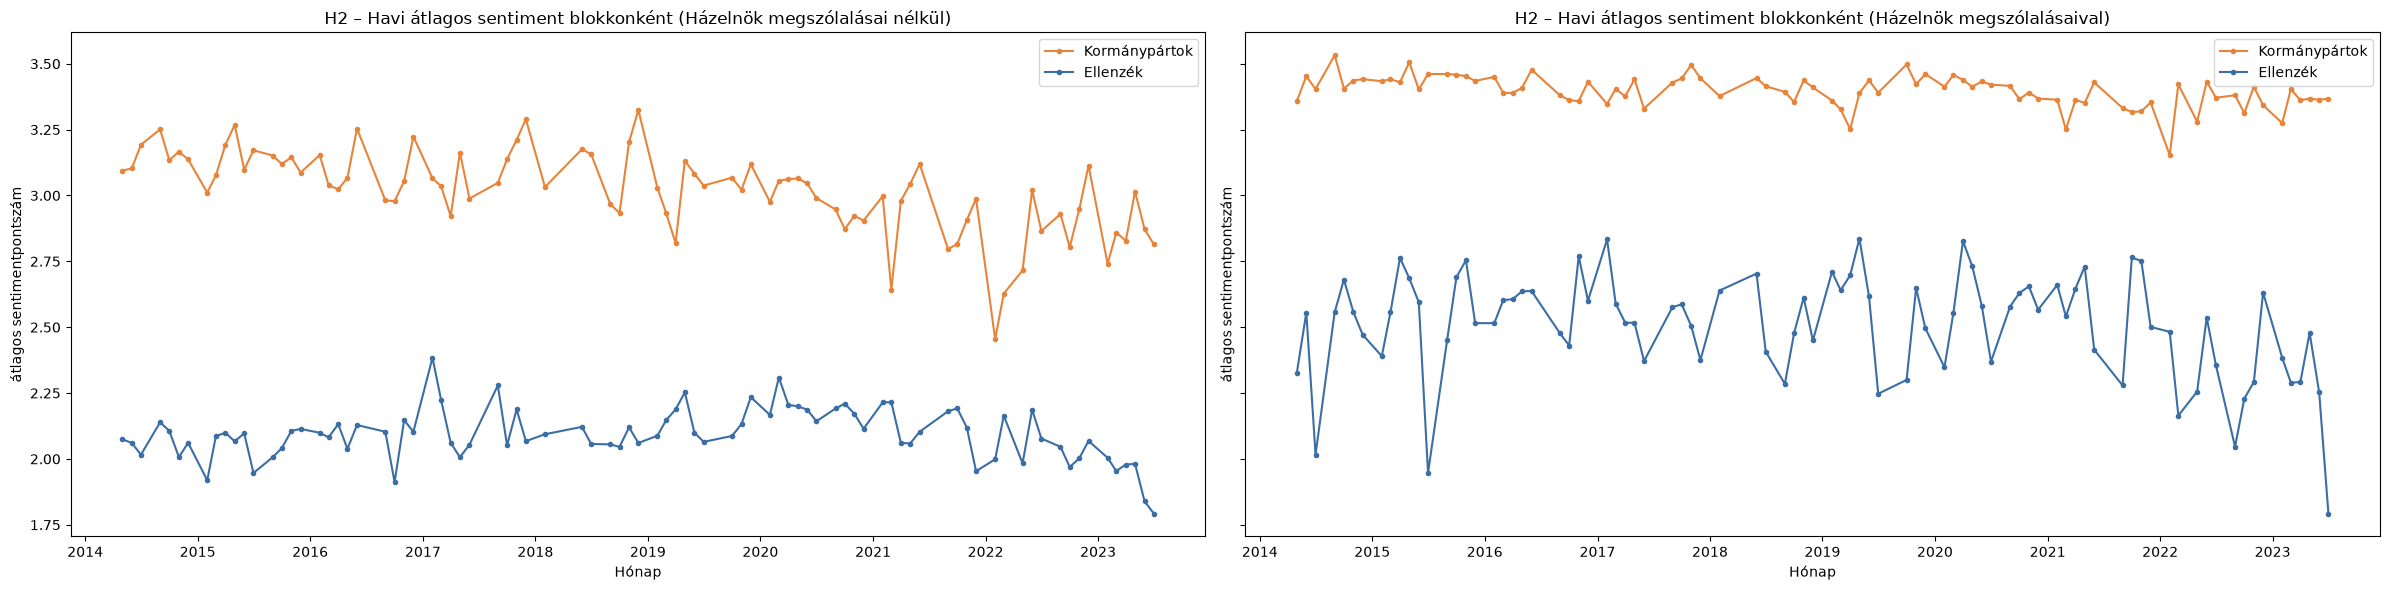

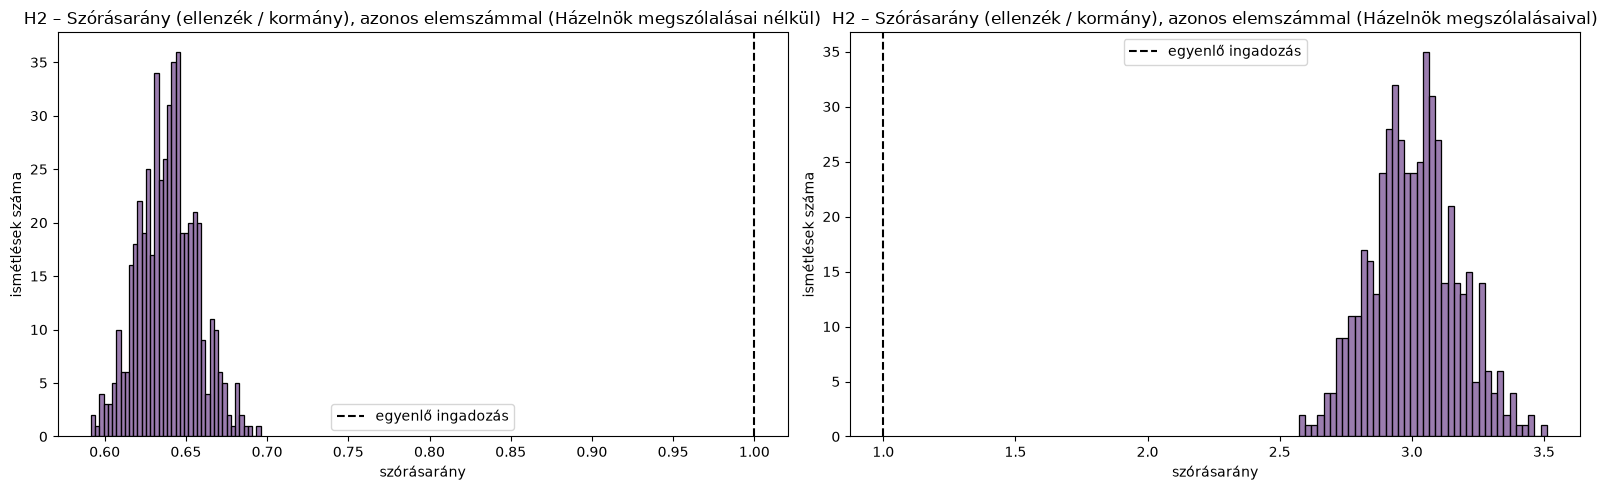

In [ ]:
# H2: a sentiment időbeli ingadozása blokkonként
MIN_HAVI_FELSZOLALAS = 20  # ennyi felszólalás kell egy hónap figyelembevételéhez
UJRAMINTAVETELEK = 500  # kiegyenlített újramintavétel ismétlésszáma
rng = np.random.default_rng(42)


# Havi átlagos sentiment blokkonként; csak azok a hónapok számítanak, ahol mindkét csoportnak elég felszólalása van.
def havi_blokk_atlagok(adat):
    havi = (
        adat.groupby(["hónap", "blokk"])["sentiment"]
        .agg(["mean", "size"])
        .unstack("blokk")
    )
    eleg = (havi["size"] >= MIN_HAVI_FELSZOLALAS).all(axis=1)
    return havi["mean"].loc[eleg, BLOKKOK].sort_index()


# mutatóink: szórás, variációs együttható, terjedelem és a hónapról hónapra történő átlagos változás
def volatilitas_mutatok(sorozat):
    valtozas = sorozat.diff().abs().dropna()
    return {
        "hónapok": len(sorozat),
        "átlag": sorozat.mean(),
        "szórás": sorozat.std(ddof=1),
        "variációs együttható": sorozat.std(ddof=1) / sorozat.mean(),
        "terjedelem": sorozat.max() - sorozat.min(),
        "IQR": sorozat.quantile(0.75) - sorozat.quantile(0.25),
        "átl. |Δ| (havi változás)": valtozas.mean(),
    }


# -----------------Brown–Forsythe-próba---------------------
# -> kétoldalú szo az irányt a szórásarány mutatja
def h2_probak(havi):
    kormany, ellenzek = havi["Kormánypártok"], havi["Ellenzék"]
    eredmeny = {
        "hónapok": len(havi),
        "szórás kormány": kormany.std(ddof=1),
        "szórás ellenzék": ellenzek.std(ddof=1),
        "szórásarány (ellenzék / kormány)": ellenzek.std(ddof=1) / kormany.std(ddof=1),
        "p (Brown–Forsythe, kétoldalú)": np.nan,
    }
    if len(havi) >= 3:
        eredmeny["p (Brown–Forsythe, kétoldalú)"] = stats.levene(
            kormany, ellenzek, center="median"
        ).pvalue
    return eredmeny


# Kontroll a mintanagyságra: az ellenzéknek kevesebb felszólalása van!
# ->, ezért hónaponként azonos számúthúzunk mindkét oldalról, és ezt sokszor megismételjük
def kiegyenlitett_ujramintavetel(adat, honapok):
    ertekek = {
        (honap, blokk): csoport["sentiment"].to_numpy()
        for (honap, blokk), csoport in adat[adat["hónap"].isin(honapok)].groupby(
            ["hónap", "blokk"]
        )
    }
    k = {honap: min(len(ertekek[(honap, b)]) for b in BLOKKOK) for honap in honapok}
    sorok = []
    for _ in range(UJRAMINTAVETELEK):
        sor = {}
        for blokk in BLOKKOK:
            atlagok = pd.Series(
                [
                    rng.choice(ertekek[(h, blokk)], size=k[h], replace=False).mean()
                    for h in honapok
                ]
            )
            sor[f"szórás {blokk}"] = atlagok.std(ddof=1)
        sorok.append(sor)
    minta = pd.DataFrame(sorok)
    minta["szórásarány"] = minta["szórás Ellenzék"] / minta["szórás Kormánypártok"]
    return minta


# futtatás és eredény kiprintelése
h2_havi, h2_eredmenyek, h2_ujraminta = {}, {}, {}
for cimke, adat in BLOKK_DATASETEK.items():
    print(f"===== H2 – {cimke} =====")
    havi = havi_blokk_atlagok(adat)
    h2_havi[cimke] = havi
    if len(havi) < 3:
        print(
            f"Kevesebb mint 3 olyan hónap van, ahol mindkét blokknak legalább {MIN_HAVI_FELSZOLALAS} felszólalása van; a H2 nem vizsgálható."
        )
        continue
    print(f"Ingadozási mutatók a havi átlagos sentiment idősorán ({len(havi)} hónap):")
    display(pd.DataFrame({b: volatilitas_mutatok(havi[b]) for b in BLOKKOK}).round(4))
    h2_eredmenyek[cimke] = h2_probak(havi)
    print("Brown–Forsythe-próba:")
    display(p_oszlopok_formazasa(pd.Series(h2_eredmenyek[cimke]).to_frame("érték").T))
    minta = kiegyenlitett_ujramintavetel(adat, havi.index)
    h2_ujraminta[cimke] = minta
    print(
        f"Kiegyenlített újramintavétel ({UJRAMINTAVETELEK} ismétlés, hónaponként azonos elemszám):"
    )
    display(
        pd.DataFrame(
            {
                "átlagos szórásarány (ellenzék / kormány)": [
                    minta["szórásarány"].mean()
                ],
                "szórásarány 95%-os intervalluma": [
                    f"{minta['szórásarány'].quantile(0.025):.3f} – {minta['szórásarány'].quantile(0.975):.3f}"
                ],
                "ellenzék szórása nagyobb (ismétlések %-a)": [
                    (minta["szórás Ellenzék"] > minta["szórás Kormánypártok"]).mean()
                    * 100
                ],
            }
        ).round(3)
    )

# ---------------------------ÁBRÁK------------------------------------
if h2_eredmenyek:
    ervenyes = [c for c in BLOKK_DATASETEK if c in h2_eredmenyek]

    # 1.Havi átlagos sentiment blokkonként
    fig, tengelyek = plt.subplots(
        1, len(ervenyes), figsize=(24, 6), sharey=True, squeeze=False
    )
    for tengely, cimke in zip(tengelyek[0], ervenyes):
        havi = h2_havi[cimke]
        for blokk in BLOKKOK:
            tengely.plot(
                havi.index,
                havi[blokk],
                marker="o",
                markersize=3,
                linewidth=1.5,
                color=blokk_szinek[blokk],
                label=blokk,
            )
        tengely.set_title(f"H2 – Havi átlagos sentiment blokkonként ({cimke})")
        tengely.set_xlabel("Hónap")
        tengely.set_ylabel("átlagos sentimentpontszám")
        tengely.legend()
    plt.tight_layout()
    plt.show()

    # 2.kiegyenlített újramintavétel: a szórásarány eloszlása
    fig, tengelyek = plt.subplots(1, len(ervenyes), figsize=(16, 5), squeeze=False)
    for tengely, cimke in zip(tengelyek[0], ervenyes):
        sns.histplot(
            h2_ujraminta[cimke]["szórásarány"], bins=40, color="#7A5195", ax=tengely
        )
        tengely.axvline(1, color="black", linestyle="--", label="egyenlő ingadozás")
        tengely.set_title(
            f"H2 – Szórásarány (ellenzék / kormány), azonos elemszámmal ({cimke})"
        )
        tengely.set_xlabel("szórásarány")
        tengely.set_ylabel("ismétlések száma")
        tengely.legend()
    plt.tight_layout()
    plt.show()

### 3.3 A H1 és a H2 összegzése

A táblázat adathalmazonként összefoglalja, mely kritériumok teljesülnek `ALFA` szignifikanciaszinten.
- **H1** akkor *támogatott*, ha a kormánypártok átlaga magasabb, és mind a Welch-féle t-próba, mind a Mann–Whitney-próba szignifikáns. Ellenkező esetben *nem támogatott*.
- **H2** akkor *támogatott*, ha az ellenzék havi átlagainak szórása nagyobb, a Brown–Forsythe-próba ezt az ellenzék javára szignifikánsnak találja (a próba kétoldalú, ezért az irányt is ellenőrizzük), és a kiegyenlített újramintavételben az ismétlések legalább 95%-ában nagyobb az ellenzék szórása. Ha ezek közül csak néhány teljesül, a döntés *részben támogatott*. Ha a Brown–Forsythe-próba ellentétes irányban szignifikáns (az ellenzék ingadozik *kevesebbet*), a döntés „nem támogatott (ellentétes irányban szignifikáns)".

**Értelmezési megjegyzések:** a nagy elemszám miatt már apró különbség is szignifikáns lehet, ezért a hatásméretet (Hedges *g*, illetve a szórásarányt) is érdemes figyelembe venni. A sentimentpontszám automatikus annotációból származik, és a kormány–ellenzék különbség részben a felszólalások típusából is adódhat: a kormányoldal gyakrabban terjeszt elő, az ellenzék gyakrabban interpellál.

In [ ]:
# A hipotézisvizsgálat összegzése mindkét adathalmazra
def reszletek_szoveg(kriteriumok):
    return ", ".join(f"{k}: {'igen' if v else 'nem'}" for k, v in kriteriumok.items())


# A H1 és a H3 közös szabályai -> az irány megfelel a hipotézisnek, és mind a Welch-féle, mind a Mann–Whitney-próba szignifikáns
def iranyos_dontes(eredmeny, irany_kriterium, megfelelo_irany):
    kriteriumok = {
        irany_kriterium: megfelelo_irany,
        "Welch-féle t szignifikáns": eredmeny["p (Welch, egyoldalú)"] < ALFA,
        "Mann–Whitney szignifikáns": eredmeny["p (Mann–Whitney, egyoldalú)"] < ALFA,
    }
    dontes = "támogatott" if all(kriteriumok.values()) else "nem támogatott"
    return dontes, reszletek_szoveg(kriteriumok)


def h1_dontes(eredmeny):
    return iranyos_dontes(
        eredmeny, "kormány átlaga magasabb", eredmeny["különbség"] > 0
    )


def h3_dontes(eredmeny):
    return iranyos_dontes(
        eredmeny, "választás előtt negatívabb", eredmeny["különbség"] < 0
    )


# sor összegző táblázatba (H1 és H3): döntés, fő mutató és részletek
def osszegzo_sor(cimke, hipotezis, eredmeny, dontes_fuggveny):
    dontes, reszlet = dontes_fuggveny(eredmeny)
    return {
        "adathalmaz": cimke,
        "hipotézis": hipotezis,
        "döntés": dontes,
        "fő mutató": f"különbség = {eredmeny['különbség']:.3f}, Hedges g = {eredmeny['Hedges g']:.3f}",
        "részletek": reszlet,
    }


def h2_dontes(eredmeny, minta):
    # A Brown–Forsythe-próba kétoldalú: szignifikáns akkor is, ha az ellenzék ingadozik kevesebbet
    # Ezért csak akkor számít a H2 melletti érvnek, ha az ellenzék szórása ténylegesen nagyobb
    nagyobb_ellenzek = eredmeny["szórásarány (ellenzék / kormány)"] > 1
    bf_szignifikans = eredmeny["p (Brown–Forsythe, kétoldalú)"] < ALFA
    kriteriumok = {
        "ellenzék szórása nagyobb": nagyobb_ellenzek,
        "Brown–Forsythe szignifikáns (az ellenzék javára)": bf_szignifikans
        and nagyobb_ellenzek,
        "újramintavételben ≥ 95%": (
            minta["szórás Ellenzék"] > minta["szórás Kormánypártok"]
        ).mean()
        >= 0.95,
    }
    # Ellentétes irány: a szórások szignifikánsan különböznek, de az ellenzéké a kisebb
    ellentetes = bf_szignifikans and not nagyobb_ellenzek
    teljesult = sum(bool(v) for v in kriteriumok.values())
    dontes = (
        "támogatott"
        if teljesult == len(kriteriumok)
        else "részben támogatott" if teljesult else "nem támogatott"
    )
    if ellentetes:
        dontes = "nem támogatott (ellentétes irányban szignifikáns)"
    reszlet = reszletek_szoveg(kriteriumok)
    if ellentetes:
        reszlet += "; a Brown–Forsythe-próba ellentétes irányban szignifikáns: az ellenzék ingadozik kevesebbet"
    return dontes, reszlet


# Táblázat az eredményekről -> H1 & H2
osszegzes = []
for cimke in BLOKK_DATASETEK:
    osszegzes.append(osszegzo_sor(cimke, "H1", h1_eredmenyek[cimke], h1_dontes))
    if cimke in h2_eredmenyek:
        dontes, reszlet = h2_dontes(h2_eredmenyek[cimke], h2_ujraminta[cimke])
        mutato = f"szórásarány = {h2_eredmenyek[cimke]['szórásarány (ellenzék / kormány)']:.3f}"
    else:
        dontes, reszlet, mutato = "nem vizsgálható", "kevés hónap", ""
    osszegzes.append(
        {
            "adathalmaz": cimke,
            "hipotézis": "H2",
            "döntés": dontes,
            "fő mutató": mutato,
            "részletek": reszlet,
        }
    )

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(osszegzes).set_index(["hipotézis", "adathalmaz"]).sort_index())

döntés  \
hipotézis adathalmaz                                                                         
H1        Házelnök megszólalásai nélkül                                         támogatott   
          Házelnök megszólalásaival                                             támogatott   
H2        Házelnök megszólalásai nélkül  nem támogatott (ellentétes irányban szignifikáns)   
          Házelnök megszólalásaival                                             támogatott   

                                                                   fő mutató  \
hipotézis adathalmaz                                                           
H1        Házelnök megszólalásai nélkül  különbség = 0.948, Hedges g = 1.149   
          Házelnök megszólalásaival      különbség = 0.831, Hedges g = 1.042   
H2        Házelnök megszólalásai nélkül                  szórásarány = 0.629   
          Házelnök megszólalásaival                      szórásarány = 3.314   

                                                                                                                                                                                                                                             részletek  
hipotézis adathalmaz                                                                                                                                                                                                                                    
H1        Házelnök megszólalásai nélkül                                                                                                                kormány átlaga magasabb: igen, Welch-féle t szignifikáns: igen, Mann–Whitney szignifikáns: igen  
          Házelnök megszólalásaival                                                                                                                    kormány átlaga magasabb: igen, Welch-féle t szignifikáns: igen, Mann–Whitney szignifikáns: igen  
H2        Házelnök megszólalásai nélkül  ellenzék szórása nagyobb: nem, Brown–Forsythe szignifikáns (az ellenzék javára): nem, újramintavételben ≥ 95%: nem; a Brown–Forsythe-próba ellentétes irányban szignifikáns: az ellenzék ingadozik kevesebbet  
          Házelnök megszólalásaival                                                                                              ellenzék szórása nagyobb: igen, Brown–Forsythe szignifikáns (az ellenzék javára): igen, újramintavételben ≥ 95%: igen

## 4. H3: a választások előtti hat hónap

**H3:** A választásokat megelőző hat hónapban a felszólalások sentimentje negatívabb, mint a választási ciklus többi részében.

**Időszakok:** az adatok két olyan országgyűlési választást fognak közre, amelyek előtt és után is van adat: **2018. április 8.** és **2022. április 3.** A *választás előtti időszak* a választást megelőző hat hónap (2017. 10. 08. – 2018. 04. 07., illetve 2021. 10. 03. – 2022. 04. 02.). Minden más felszólalás a *ciklus többi része*, a 2022-es választás utáni időszakkal együtt. A 2014-es választás (április 6.) előttről nincs adat. A választások listája a `VALASZTASOK`, az időablak hossza az `ELOTTE_HONAP` beállítással módosítható.

**Próbák (egyoldalúak: választás előtt < ciklus többi része):** a 3.1 szakaszhoz hasonlóan feltételezzük, hogy a felszólalások függetlenek egymástól, ezért felszólalás-szinten Welch-féle t-próbát és Mann–Whitney U-próbát használunk, hatásméretként Hedges *g*-t.

**Kiegészítő elemzések:** választási ciklusonkénti bontás (külön a 2014–2018-as és a 2018–2022-es ciklusra), bontás kormánypárt/ellenzék és bal/jobb szerint, valamint a választáshoz viszonyított havi átlagok ábrája (eseményvizsgálat).

===== H3 – Házelnök megszólalásai nélkül =====
Leíró statisztika (felszólalás-szint):


,n,átlag,medián,szórás,CI95_alsó,CI95_felső
időszak,,,,,,
választás előtti 6 hónap,3995,2.5984,2.4689,0.990,2.5677,2.6291
ciklus többi része,48336,2.5440,2.4230,0.948,2.5356,2.5525


Hipotézistesztek (egyoldalú: választás előtt < ciklus többi része):


,n előtte,n többi,átlag választás előtt,átlag ciklus többi része,különbség,t,"p (Welch, egyoldalú)","p (Mann–Whitney, egyoldalú)",Hedges g,rang-biszeriális r
felszólalás,3995,48336,2.5984,2.544,0.0544,3.3478,9.996e-01,9.992e-01,0.0572,0.0298


Választási ciklusonként (a 2022–2026-os ciklusban nincs választás előtti adat):


,n előtte,n többi,átlag előtte,átlag többi,különbség,t,"p (Welch, egyoldalú)",Hedges g
ciklus,,,,,,,,
2014–2018,2371,23356,2.6613,2.5442,0.1171,5.4641,1.000e+00,0.1248
2018–2022,1624,18949,2.5067,2.5742,-0.0675,-2.6990,3.508e-03,-0.0698


... (10 outputs left out)

Kormánypártok és ellenzék szerint:


,n előtte,n többi,átlag előtte,átlag többi,különbség,t,"p (Welch, egyoldalú)",Hedges g
blokk,,,,,,,,
Kormánypártok,5380,60877,3.3993,3.4055,-0.0062,-0.6294,2.645e-01,-0.0094
Ellenzék,2829,38756,2.5921,2.5725,0.0197,1.0047,8.424e-01,0.0202


Bal- és jobboldal szerint:


,n előtte,n többi,átlag előtte,átlag többi,különbség,t,"p (Welch, egyoldalú)",Hedges g
politikai_pólus,,,,,,,,
Baloldal,1689,22781,2.5053,2.5247,-0.0194,-0.7641,2.224e-01,-0.0195
Jobboldal,6533,76610,3.2816,3.2528,0.0288,2.8026,9.975e-01,0.0367
Közép/egyéb,2,389,1.1751,1.9944,-0.8194,-11.1586,3.710e-03,-1.0328


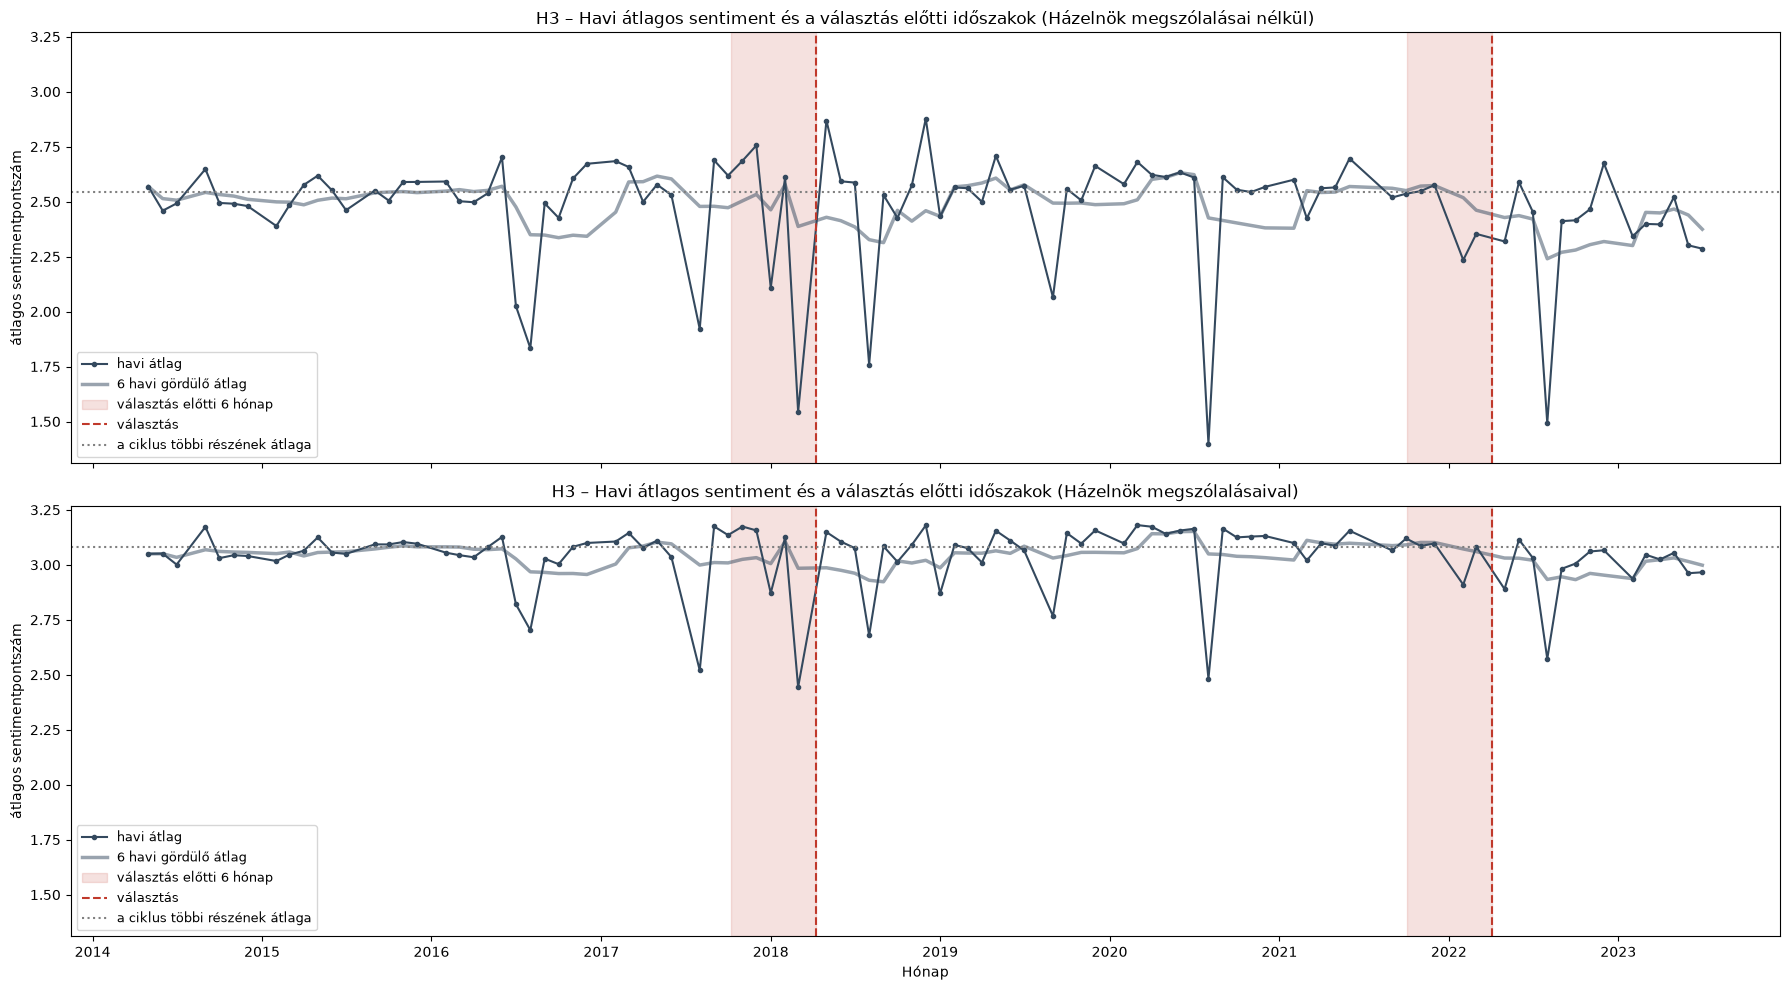

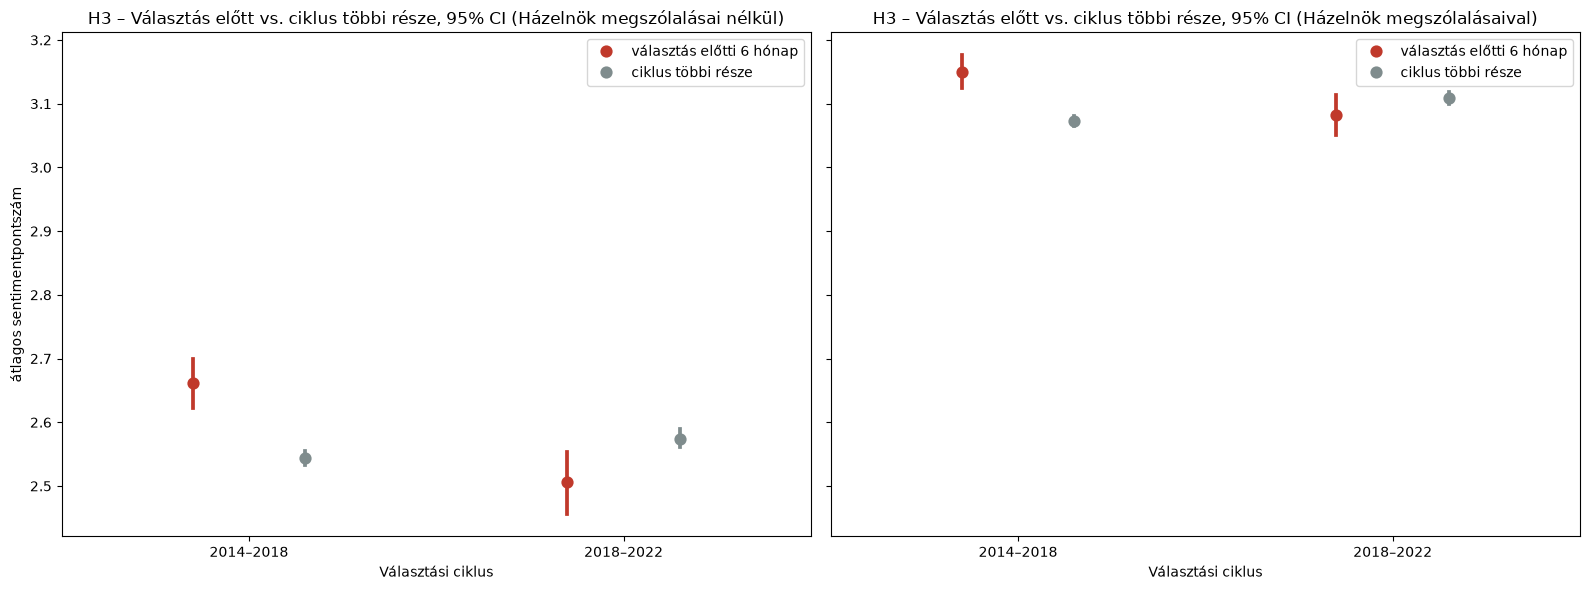

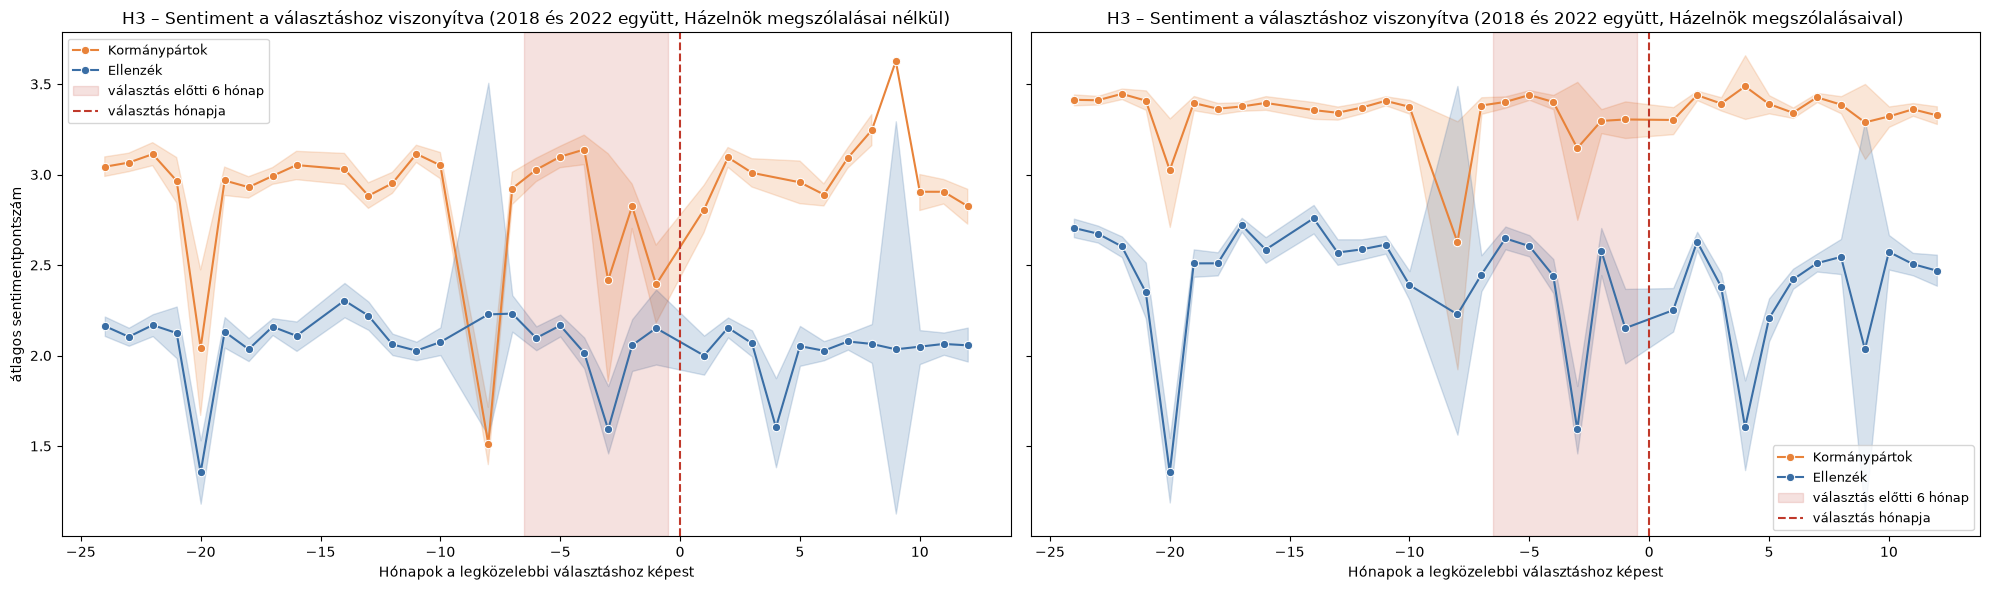

H3 döntés:


döntés  \
hipotézis adathalmaz                                      
H3        Házelnök megszólalásai nélkül  nem támogatott   
          Házelnök megszólalásaival      nem támogatott   

                                                                   fő mutató  \
hipotézis adathalmaz                                                           
H3        Házelnök megszólalásai nélkül  különbség = 0.054, Hedges g = 0.057   
          Házelnök megszólalásaival      különbség = 0.040, Hedges g = 0.045   

                                                                                                                               részletek  
hipotézis adathalmaz                                                                                                                      
H3        Házelnök megszólalásai nélkül  választás előtt negatívabb: nem, Welch-féle t szignifikáns: nem, Mann–Whitney szignifikáns: nem  
          Házelnök megszólalásaival      választás előtt negatívabb: nem, Welch-féle t szignifikáns: nem, Mann–Whitney szignifikáns: nem

In [ ]:
VALASZTASOK = pd.to_datetime(["2018-04-08", "2022-04-03"])
ELOTTE_HONAP = 6
IDOSZAKOK = ["választás előtti 6 hónap", "ciklus többi része"]
CIKLUSOK = ["2014–2018", "2018–2022", "2022–2026"]
IDOSZAK_SZINEK = {IDOSZAKOK[0]: "#C0392B", IDOSZAKOK[1]: "#7F8C8D"}


# választás előtti 6 hónapba esik-e
def valasztas_elotti(datumok):

    elotte = pd.Series(False, index=datumok.index)
    for valasztas in VALASZTASOK:
        elotte |= (datumok >= valasztas - pd.DateOffset(months=ELOTTE_HONAP)) & (
            datumok < valasztas
        )
    return elotte


# választás előtti időszakba tartozik-e?
# melyik ciklusban volt?
# hány hónapra van a legközelebbi választástól?
def h3_elokeszites(adat):
    datumok = adat["dátum"]
    ciklus_index = np.searchsorted(VALASZTASOK.values, datumok.values, side="right")
    # a legközelebbi választáshoz viszonyított hónap (negatív: előtte, pozitív: utána)
    relativ = np.stack(
        [
            (datumok.dt.year - v.year) * 12 + (datumok.dt.month - v.month)
            for v in VALASZTASOK
        ]
    )
    tavolsag = np.stack([(datumok - v).abs().dt.days for v in VALASZTASOK])
    legkozelebbi = tavolsag.argmin(axis=0)
    return adat.assign(
        időszak=np.where(valasztas_elotti(datumok), IDOSZAKOK[0], IDOSZAKOK[1]),
        ciklus=[CIKLUSOK[i] for i in ciklus_index],
        legközelebbi_választás=[
            VALASZTASOK[i].strftime("%Y-%m-%d") for i in legkozelebbi
        ],
        relatív_hónap=relativ[legkozelebbi, np.arange(len(adat))],
    )


# datasetek kiegészítése (választás előtti időszak és a ciklus többi része & ciklus & relatív hónap)
H3_DATASETEK = {cimke: h3_elokeszites(adat) for cimke, adat in DATASETEK.items()}
H3_BLOKK_DATASETEK = {
    cimke: h3_elokeszites(adat) for cimke, adat in BLOKK_DATASETEK.items()
}


# egyoldalú próbák arra, hogy a választás előtti értékek kisebbek (negatívabbak), mint a többi időszakban
def kisebb_e(elotte, tobbi):
    return {
        "n előtte": len(elotte),
        "n többi": len(tobbi),
        "átlag választás előtt": elotte.mean(),
        "átlag ciklus többi része": tobbi.mean(),
        **csoportok_osszevetese(elotte, tobbi, "less"),
    }


# választás előtti időszak és a ciklus többi részének összevetése ->felszólalásonkénti
def h3_elemzes(adat):
    return kisebb_e(
        adat.loc[adat["időszak"] == IDOSZAKOK[0], "sentiment"],
        adat.loc[adat["időszak"] == IDOSZAKOK[1], "sentiment"],
    )


# -> részcsoportonkénti (ciklus, kormány/ellenzék, bal/jobb)
def h3_bontas(adat, csoport, csoportok):

    sorok = []
    for ertek in csoportok:
        resz = adat[adat[csoport] == ertek]
        elotte = resz.loc[resz["időszak"] == IDOSZAKOK[0], "sentiment"]
        tobbi = resz.loc[resz["időszak"] == IDOSZAKOK[1], "sentiment"]
        if len(elotte) < 2 or len(tobbi) < 2:
            continue
        sorok.append(
            {
                csoport: ertek,
                "n előtte": len(elotte),
                "n többi": len(tobbi),
                "átlag előtte": elotte.mean(),
                "átlag többi": tobbi.mean(),
                **csoportok_osszevetese(elotte, tobbi, "less", mann_whitney=False),
            }
        )
    tabla = pd.DataFrame(sorok)
    return tabla.set_index(csoport) if not tabla.empty else tabla


# futtatás mindkét adathalmazra, és print táblázat
h3_eredmenyek = {}
for cimke, adat in H3_DATASETEK.items():
    print(f"===== H3 – {cimke} =====")
    print("Leíró statisztika (felszólalás-szint):")
    display(leiro_statisztika(adat, "időszak").reindex(IDOSZAKOK).round(4))
    h3_eredmenyek[cimke] = h3_elemzes(adat)
    print("Hipotézistesztek (egyoldalú: választás előtt < ciklus többi része):")
    display(
        p_oszlopok_formazasa(
            pd.DataFrame([h3_eredmenyek[cimke]], index=["felszólalás"])
        )
    )
    print(
        "Választási ciklusonként (a 2022–2026-os ciklusban nincs választás előtti adat):"
    )
    display(p_oszlopok_formazasa(h3_bontas(adat, "ciklus", CIKLUSOK)))
    print("Kormánypártok és ellenzék szerint:")
    display(
        p_oszlopok_formazasa(h3_bontas(H3_BLOKK_DATASETEK[cimke], "blokk", BLOKKOK))
    )
    print("Bal- és jobboldal szerint:")
    display(
        p_oszlopok_formazasa(
            h3_bontas(adat, "politikai_pólus", ["Baloldal", "Jobboldal", "Közép/egyéb"])
        )
    )

# --------------ábrák--------------------------
# 1. Havi átlagos sentiment a választás előtti időszakok kiemelésével
fig, tengelyek = plt.subplots(
    len(H3_DATASETEK), 1, figsize=(18, 5 * len(H3_DATASETEK)), sharex=True, sharey=True
)
for tengely, (cimke, adat) in zip(np.atleast_1d(tengelyek), H3_DATASETEK.items()):
    havi = adat.groupby("hónap")["sentiment"].mean()
    tengely.plot(
        havi.index,
        havi.values,
        marker="o",
        markersize=3,
        color="#34495E",
        label="havi átlag",
    )
    tengely.plot(
        havi.index,
        havi.rolling(6, min_periods=1).mean(),
        color="#34495E",
        linewidth=2.5,
        alpha=0.5,
        label="6 havi gördülő átlag",
    )
    for i, valasztas in enumerate(VALASZTASOK):
        tengely.axvspan(
            valasztas - pd.DateOffset(months=ELOTTE_HONAP),
            valasztas,
            color=IDOSZAK_SZINEK[IDOSZAKOK[0]],
            alpha=0.15,
            label=IDOSZAKOK[0] if i == 0 else None,
        )
        tengely.axvline(
            valasztas,
            color=IDOSZAK_SZINEK[IDOSZAKOK[0]],
            linestyle="--",
            label="választás" if i == 0 else None,
        )
    tengely.axhline(
        adat.loc[adat["időszak"] == IDOSZAKOK[1], "sentiment"].mean(),
        color="grey",
        linestyle=":",
        label="a ciklus többi részének átlaga",
    )
    tengely.set_title(
        f"H3 – Havi átlagos sentiment és a választás előtti időszakok ({cimke})"
    )
    tengely.set_ylabel("átlagos sentimentpontszám")
    tengely.legend(loc="lower left", fontsize=9)
tengely.set_xlabel("Hónap")
plt.tight_layout()
plt.show()

# 2. Választás előtt vs. többi rész ciklusonként, 95% CI
fig, tengelyek = plt.subplots(1, len(H3_DATASETEK), figsize=(16, 6), sharey=True)
for tengely, (cimke, adat) in zip(np.atleast_1d(tengelyek), H3_DATASETEK.items()):
    sns.pointplot(
        data=adat[adat["ciklus"].isin(CIKLUSOK[:2])],
        x="ciklus",
        y="sentiment",
        hue="időszak",
        order=CIKLUSOK[:2],
        hue_order=IDOSZAKOK,
        palette=IDOSZAK_SZINEK,
        errorbar=("ci", 95),
        dodge=0.3,
        linestyle="none",
        ax=tengely,
    )
    tengely.set_title(f"H3 – Választás előtt vs. ciklus többi része, 95% CI ({cimke})")
    tengely.set_xlabel("Választási ciklus")
    tengely.set_ylabel("átlagos sentimentpontszám")
    tengely.legend(title="")
plt.tight_layout()
plt.show()

# 3.eseményvizsgálat: átlag a választáshoz viszonyított hónapok szerint, blokkonként
fig, tengelyek = plt.subplots(1, len(H3_BLOKK_DATASETEK), figsize=(20, 6), sharey=True)
for tengely, (cimke, adat) in zip(np.atleast_1d(tengelyek), H3_BLOKK_DATASETEK.items()):
    ablak = adat[adat["relatív_hónap"].between(-24, 12)]
    sns.lineplot(
        data=ablak,
        x="relatív_hónap",
        y="sentiment",
        hue="blokk",
        hue_order=BLOKKOK,
        palette=blokk_szinek,
        estimator="mean",
        errorbar=("ci", 95),
        marker="o",
        ax=tengely,
    )
    tengely.axvspan(
        -ELOTTE_HONAP - 0.5,
        -0.5,
        color=IDOSZAK_SZINEK[IDOSZAKOK[0]],
        alpha=0.15,
        label=IDOSZAKOK[0],
    )
    tengely.axvline(
        0, color=IDOSZAK_SZINEK[IDOSZAKOK[0]], linestyle="--", label="választás hónapja"
    )
    tengely.set_title(
        f"H3 – Sentiment a választáshoz viszonyítva (2018 és 2022 együtt, {cimke})"
    )
    tengely.set_xlabel("Hónapok a legközelebbi választáshoz képest")
    tengely.set_ylabel("átlagos sentimentpontszám")
    tengely.legend(title="", fontsize=9)
plt.tight_layout()
plt.show()


# Összegző táblázat a H3ról
h3_osszegzes = [
    osszegzo_sor(cimke, "H3", eredmeny, h3_dontes)
    for cimke, eredmeny in h3_eredmenyek.items()
]
print("H3 döntés:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(h3_osszegzes).set_index(["hipotézis", "adathalmaz"]))

## 5. Válasz a K1 kutatási kérdésre

A K1 két összevetést kérdez: **kormánypárt–ellenzék** (H1, H2) és **bal–jobb**. A táblázat a hipotézisek döntéseit (a 3. és 4. fejezetből) és a bal- és jobboldal átlagos sentimentjének különbségét (Welch-féle t-próba, kétoldalú, ugyanúgy, mint a 2.3 szakaszban) foglalja össze, mindkét adathalmazra.

**Értelmezési megjegyzés:** a nagy elemszám miatt már apró különbség is szignifikáns lehet, ezért a hatásméretet is figyelembe kell venni. Hedges *g* esetén ökölszabályként 0,2 körül kicsi, 0,5 körül közepes, 0,8 fölött nagy hatásról beszélünk.

In [ ]:
# K1 összesítés
# kormánypárt–ellenzék (H1–H3) és bal–jobb különbség
# a bal–jobb különbséget is megvizsgáljuk -> kétoldalú Welch-próba, hatásmérettel
bal_jobb_sorok = []
for cimke, adat in DATASETEK.items():
    bal = adat.loc[adat["politikai_pólus"] == "Baloldal", "sentiment"]
    jobb = adat.loc[adat["politikai_pólus"] == "Jobboldal", "sentiment"]
    teszt = csoportok_osszevetese(jobb, bal, mann_whitney=False)
    p_ertek = teszt["p (Welch, kétoldalú)"]
    bal_jobb_sorok.append(
        {
            "adathalmaz": cimke,
            "hipotézis": "K1 bal–jobb",
            "döntés": (
                "szignifikáns különbség"
                if p_ertek < ALFA
                else "nincs szignifikáns különbség"
            ),
            "fő mutató": f"jobb − bal = {teszt['különbség']:.3f}, Hedges g = {teszt['Hedges g']:.3f}",
            "részletek": f"Welch t = {teszt['t']:.2f}, p = {formazott_p(p_ertek)} (kétoldalú); "
            f"átlag: baloldal {bal.mean():.3f}, jobboldal {jobb.mean():.3f}",
        }
    )

# Egy táblázatba rakjuk a H1, H2, H3 és a bal–jobb összevetés eredményét.
k1_osszegzes = pd.DataFrame(osszegzes + h3_osszegzes + bal_jobb_sorok)
k1_osszegzes["hipotézis"] = pd.Categorical(
    k1_osszegzes["hipotézis"], ["H1", "H2", "H3", "K1 bal–jobb"], ordered=True
)
k1_osszegzes["adathalmaz"] = pd.Categorical(
    k1_osszegzes["adathalmaz"], list(DATASETEK), ordered=True
)
k1_osszegzes = k1_osszegzes.sort_values(["hipotézis", "adathalmaz"]).set_index(
    ["hipotézis", "adathalmaz"]
)
with pd.option_context("display.max_colwidth", None):
    display(k1_osszegzes)

döntés  \
hipotézis   adathalmaz                                                                         
H1          Házelnök megszólalásai nélkül                                         támogatott   
            Házelnök megszólalásaival                                             támogatott   
H2          Házelnök megszólalásai nélkül  nem támogatott (ellentétes irányban szignifikáns)   
            Házelnök megszólalásaival                                             támogatott   
H3          Házelnök megszólalásai nélkül                                     nem támogatott   
            Házelnök megszólalásaival                                         nem támogatott   
K1 bal–jobb Házelnök megszólalásai nélkül                             szignifikáns különbség   
            Házelnök megszólalásaival                                 szignifikáns különbség   

                                                                      fő mutató  \
hipotézis   adathalmaz                                                            
H1          Házelnök megszólalásai nélkül   különbség = 0.948, Hedges g = 1.149   
            Házelnök megszólalásaival       különbség = 0.831, Hedges g = 1.042   
H2          Házelnök megszólalásai nélkül                   szórásarány = 0.629   
            Házelnök megszólalásaival                       szórásarány = 3.314   
H3          Házelnök megszólalásai nélkül   különbség = 0.054, Hedges g = 0.057   
            Házelnök megszólalásaival       különbség = 0.040, Hedges g = 0.045   
K1 bal–jobb Házelnök megszólalásai nélkül  jobb − bal = 0.701, Hedges g = 0.785   
            Házelnök megszólalásaival      jobb − bal = 0.732, Hedges g = 0.874   

                                                                                                                                                                                                                                               részletek  
hipotézis   adathalmaz                                                                                                                                                                                                                                    
H1          Házelnök megszólalásai nélkül                                                                                                                kormány átlaga magasabb: igen, Welch-féle t szignifikáns: igen, Mann–Whitney szignifikáns: igen  
            Házelnök megszólalásaival                                                                                                                    kormány átlaga magasabb: igen, Welch-féle t szignifikáns: igen, Mann–Whitney szignifikáns: igen  
H2          Házelnök megszólalásai nélkül  ellenzék szórása nagyobb: nem, Brown–Forsythe szignifikáns (az ellenzék javára): nem, újramintavételben ≥ 95%: nem; a Brown–Forsythe-próba ellentétes irányban szignifikáns: az ellenzék ingadozik kevesebbet  
            Házelnök megszólalásaival                                                                                              ellenzék szórása nagyobb: igen, Brown–Forsythe szignifikáns (az ellenzék javára): igen, újramintavételben ≥ 95%: igen  
H3          Házelnök megszólalásai nélkül                                                                                                                választás előtt negatívabb: nem, Welch-féle t szignifikáns: nem, Mann–Whitney szignifikáns: nem  
            Házelnök megszólalásaival                                                                                                                    választás előtt negatívabb: nem, Welch-féle t szignifikáns: nem, Mann–Whitney szignifikáns: nem  
K1 bal–jobb Házelnök megszólalásai nélkül                                                                                                                              Welch t = 87.21, p = < 1e-300 (kétoldalú); átlag: baloldal 2.081, jobboldal 2.782  
            Házelnök megszólalásaiv

## 6. Kiegészítő elemzések

Ezek az elemzések nem szükségesek a K1 megválaszolásához, de a háttér megértését segítik: kik a legnagyobb hatású szereplők, és miről beszélnek a pártok.

### 6.1 Kulcsszereplők és szélsőséges hangok

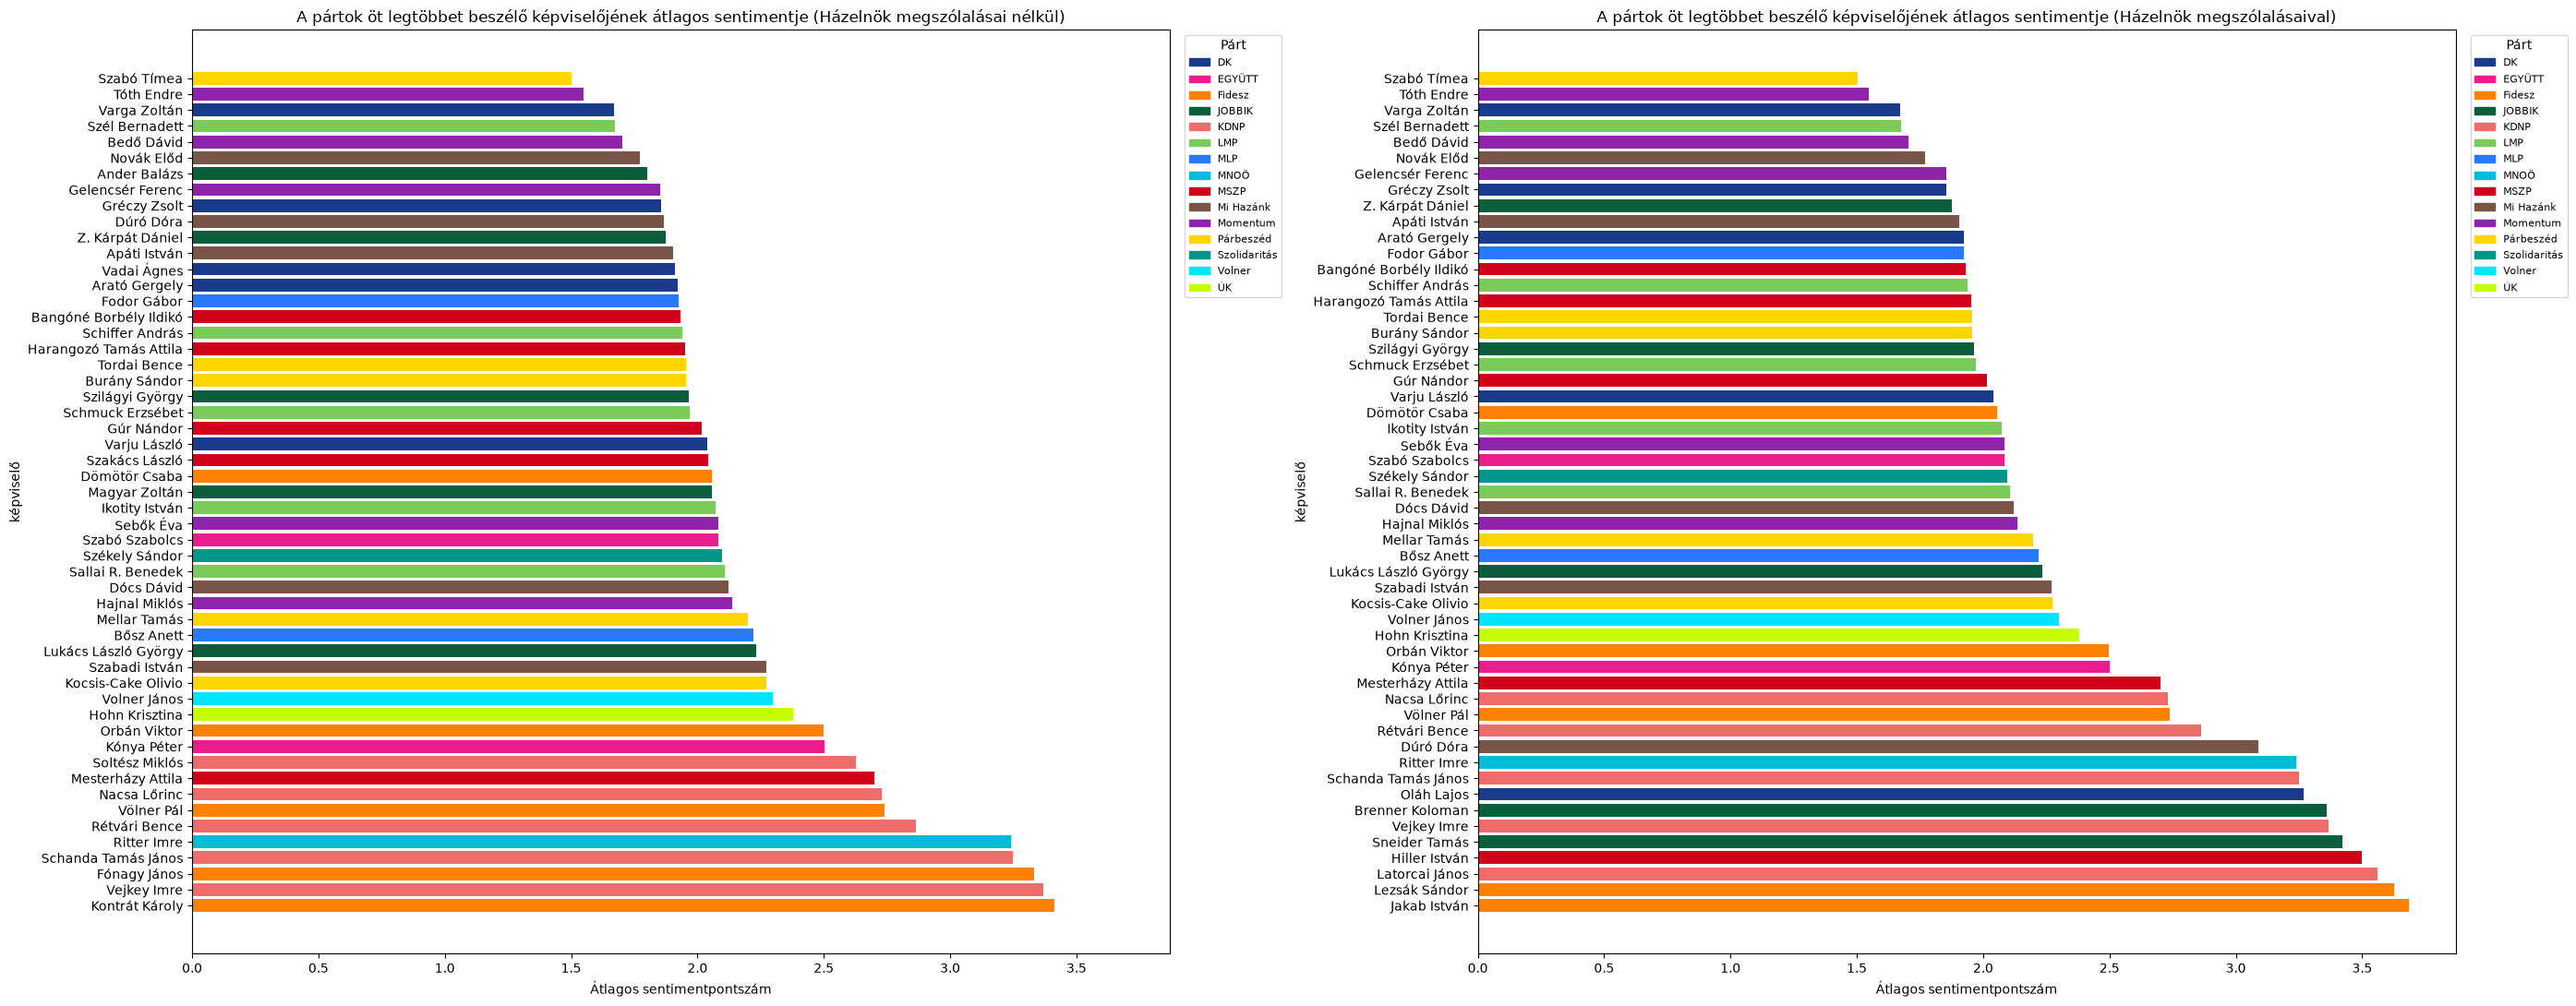

===== Házelnök megszólalásai nélkül =====
Legpozitívabb és legnegatívabb beszélők, legalább 50 felszólalással:
Baloldal - legpozitívabb


,politikai_polus,párt,képviselő,felszolalasok,elnoki_felszolalasok,atlagos_sentiment
43,Baloldal,MSZP,Hiszékeny Dezső,250,0,2.785908
52,Baloldal,MSZP,Mesterházy Attila,561,0,2.701157
50,Baloldal,MSZP,Legény Zsolt,213,0,2.687584
36,Baloldal,MSZP,Gurmai Zita,300,0,2.491813
53,Baloldal,MSZP,Molnár Gyula,121,0,2.456239


Baloldal - legnegatívabb


,politikai_polus,párt,képviselő,felszolalasok,elnoki_felszolalasok,atlagos_sentiment
75,Baloldal,Párbeszéd,Szabó Tímea,224,0,1.502023
18,Baloldal,DK,Varga Zoltán,254,0,1.670802
30,Baloldal,LMP,Szél Bernadett,522,0,1.673716
74,Baloldal,Párbeszéd,Szabó Rebeka,81,0,1.813007
51,Baloldal,MSZP,Lukács Zoltán,74,0,1.829203


Jobboldal - legpozitívabb


,politikai_polus,párt,képviselő,felszolalasok,elnoki_felszolalasok,atlagos_sentiment
193,Jobboldal,Fidesz,Szabó Tünde,56,0,4.037359
291,Jobboldal,KDNP,Szászfalvi László,205,0,3.756449
270,Jobboldal,KDNP,Firtl Mátyás,139,0,3.726941
170,Jobboldal,Fidesz,Nyitrai Zsolt,83,0,3.726197
141,Jobboldal,Fidesz,Kara Ákos,93,0,3.696466


... (20 outputs left out)

Pártonkénti szélsőértékek:


,politikai_polus,párt,képviselő,felszolalasok,elnoki_felszolalasok,atlagos_sentiment
13,Baloldal,DK,Oláh Lajos,516,415,3.270229
18,Baloldal,DK,Varga Zoltán,254,0,1.670802
307,Közép/egyéb,EGYÜTT,Szabó Szabolcs,79,0,2.084160
307,Közép/egyéb,EGYÜTT,Szabó Szabolcs,79,0,2.084160
193,Jobboldal,Fidesz,Szabó Tünde,56,0,4.037359
144,Jobboldal,Fidesz,Kocsis Máté,80,0,1.999071
255,Jobboldal,JOBBIK,Sneider Tamás,5570,5474,3.420602
227,Jobboldal,JOBBIK,Apáti István,140,0,1.781304
291,Jobboldal,KDNP,Szászfalvi László,205,0,3.756449
290,Jobboldal,KDNP,Soltész Miklós,291,0,2.626156


Elnöki felszólalással rendelkező beszélők: átlagos sentiment a két adathalmazban


,politikai_polus,párt,képviselő,felszolalasok,elnoki_felszolalasok,atlagos_sentiment,felszolalasok_chair_nelkul,atlagos_sentiment_chair_nelkul,sentiment_kulonbseg
140,Jobboldal,Fidesz,Jakab István,14713,14689,3.6855,24,3.1901,0.4954
279,Jobboldal,KDNP,Latorcai János,13957,13911,3.5625,46,3.3438,0.2186
156,Jobboldal,Fidesz,Lezsák Sándor,12305,12299,3.6272,6,3.0848,0.5424
42,Baloldal,MSZP,Hiller István,7217,7048,3.4970,169,2.1967,1.3004
255,Jobboldal,JOBBIK,Sneider Tamás,5570,5474,3.4206,96,2.1505,1.2701
232,Jobboldal,JOBBIK,Brenner Koloman,953,759,3.3613,194,2.4734,0.8878
298,Jobboldal,Mi Hazánk,Dúró Dóra,682,579,3.0895,103,1.8655,1.2241
154,Jobboldal,Fidesz,Kövér László,467,463,3.2806,4,3.5543,-0.2737
13,Baloldal,DK,Oláh Lajos,516,415,3.2702,101,1.9560,1.3143
206,Jobboldal,Fidesz,Turi-Kovács Béla,124,36,2.8564,88,2.6563,0.2001


In [ ]:
# A pártok kulcsszereplői és szélsőséges hangjai, mindkét adathalmazon

# Pártszínek, a népszerű pártoknak továbbra is a megadott színeket használjuk
TOVABBI_PART_SZINEK = {
    "Mi Hazánk": "#795548",
    "Momentum": "#8E24AA",
    "Párbeszéd": "#FFD600",
    "EGYÜTT": "#E91E8C",
    "MLP": "#2979FF",
    "Szolidaritás": "#009688",
    "ÚK": "#C6FF00",
    "Volner": "#00E5FF",
    "MNOÖ": "#00BCD4",
}
FELTUNO_ALAPSZIN = "#FF00FF"  # tartalék: ha egy pártnak egyik szótárban sincs színe
PART_SZIN_OSSZES = {
    **TOVABBI_PART_SZINEK,
    **PART_SZINEK,
}  # a megadott színek elsőbbséget élveznek


# Képviselőnként összesíti a felszólalások számát, ebből az elnökiekét, és az átlagos sentimentet.
def kepviselo_osszefoglalo(adat):
    """Képviselőnkénti felszólalásszám, elnöki felszólalásszám és átlagos sentiment."""
    return (
        adat.assign(elnoki=adat["szerep"].isin(KIZART_SZEREPEK))
        .groupby(["politikai_pólus", "párt", "beszélő"], as_index=False)
        .agg(
            felszolalasok=("sentiment", "size"),
            elnoki_felszolalasok=("elnoki", "sum"),
            atlagos_sentiment=("sentiment", "mean"),
        )
        .rename(columns={"politikai_pólus": "politikai_polus", "beszélő": "képviselő"})
    )


MIN_FELSZOLALAS = (
    50  # ennyi felszólalás alatt a képviselő nem kerül a szélsőérték-listákba
)
# Mindkét adathalmazra elkészítjük az összefoglalót.
kepviselok = {cimke: kepviselo_osszefoglalo(adat) for cimke, adat in DATASETEK.items()}

# 1) Pártonként az öt legtöbbet beszélő képviselő, a két adathalmaz egymás mellett
# A képviselők átlagos sentiment szerint növekvő sorrendben szerepelnek (felül a legkisebb), a sáv színe a párté.
fig, tengelyek = plt.subplots(1, len(DATASETEK), figsize=(28, 11), sharex=True)
for tengely, (cimke, osszefoglalo) in zip(tengelyek, kepviselok.items()):
    # Minden pártból az öt legtöbbet felszólaló képviselő, majd növekvő sentiment szerinti sorrend.
    top5 = (
        osszefoglalo.sort_values(["párt", "felszolalasok"], ascending=[True, False])
        .groupby("párt", group_keys=False)
        .head(5)
        .sort_values("atlagos_sentiment")
        .reset_index(drop=True)
    )
    szinek = top5["párt"].map(lambda part: PART_SZIN_OSSZES.get(part, FELTUNO_ALAPSZIN))
    tengely.barh(top5.index, top5["atlagos_sentiment"], color=szinek)
    tengely.set_yticks(top5.index, top5["képviselő"])
    tengely.invert_yaxis()  # a legkisebb átlagú képviselő kerül felülre
    tengely.set_title(
        f"A pártok öt legtöbbet beszélő képviselőjének átlagos sentimentje ({cimke})"
    )
    tengely.set_xlabel("Átlagos sentimentpontszám")
    tengely.set_ylabel("képviselő")
    # Jelmagyarázat: csak az ábrán szereplő pártok, ábécésorrendben.
    tengely.legend(
        handles=[
            Patch(color=PART_SZIN_OSSZES.get(part, FELTUNO_ALAPSZIN), label=part)
            for part in sorted(top5["párt"].unique())
        ],
        title="Párt",
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        fontsize=8,
    )
plt.tight_layout()
plt.show()

# 2) Legpozitívabb és legnegatívabb beszélők, legalább MIN_FELSZOLALAS felszólalással
for cimke, osszefoglalo in kepviselok.items():
    # Csak a legalább MIN_FELSZOLALAS felszólalású képviselők kerülnek be (különben néhány beszéd torzítaná az átlagot).
    speaker_50 = osszefoglalo[osszefoglalo["felszolalasok"] >= MIN_FELSZOLALAS]
    print(f"===== {cimke} =====")
    if speaker_50.empty:
        print(f"Nincs legalább {MIN_FELSZOLALAS} felszólalással rendelkező képviselő.")
        continue
    print(
        f"Legpozitívabb és legnegatívabb beszélők, legalább {MIN_FELSZOLALAS} felszólalással:"
    )
    for oldal, group in speaker_50.groupby("politikai_polus"):
        print(f"{oldal} - legpozitívabb")
        display(group.nlargest(5, "atlagos_sentiment"))
        print(f"{oldal} - legnegatívabb")
        display(group.nsmallest(5, "atlagos_sentiment"))
    # Pártonként a legpozitívabb és a legnegatívabb képviselő.
    print("Pártonkénti szélsőértékek:")
    display(
        pd.concat(
            [
                pd.concat(
                    [
                        group.nlargest(1, "atlagos_sentiment"),
                        group.nsmallest(1, "atlagos_sentiment"),
                    ]
                )
                for _, group in speaker_50.groupby("párt")
            ]
        )
    )

# 3) Kiket érint leginkább a #chair: a legtöbb elnöki felszólalással rendelkező beszélők
# Összekötjük a két adathalmaz képviselői átlagait: látszik, kinek mennyit változik az átlaga az elnöki felszólalásoktól.
elnoki_hatas = (
    kepviselok[CIMKE_TELJES]
    .merge(
        kepviselok[CIMKE_SZURT][
            ["párt", "képviselő", "felszolalasok", "atlagos_sentiment"]
        ],
        on=["párt", "képviselő"],
        how="left",
        suffixes=("", "_chair_nelkul"),
    )
    .query("elnoki_felszolalasok > 0")
    .assign(
        sentiment_kulonbseg=lambda t: t["atlagos_sentiment"]
        - t["atlagos_sentiment_chair_nelkul"]
    )
    .sort_values("elnoki_felszolalasok", ascending=False)
)
print(
    "Elnöki felszólalással rendelkező beszélők: átlagos sentiment a két adathalmazban"
)
display(elnoki_hatas.round(4))

### 6.2 Témaelemzés

A témaelemzés az 1. fejezetben beolvasott adatkeretből indul ki, és csak a témakódok nevét olvassa be külön. A témák megoszlását makro- (bal/jobb), párt- és képviselői szinten mutatja be.

Témával és pártaffiliációval rendelkező felszólalások (Házelnök megszólalásai nélkül): 52 331
Témával és pártaffiliációval rendelkező felszólalások (Házelnök megszólalásaival): 108 003


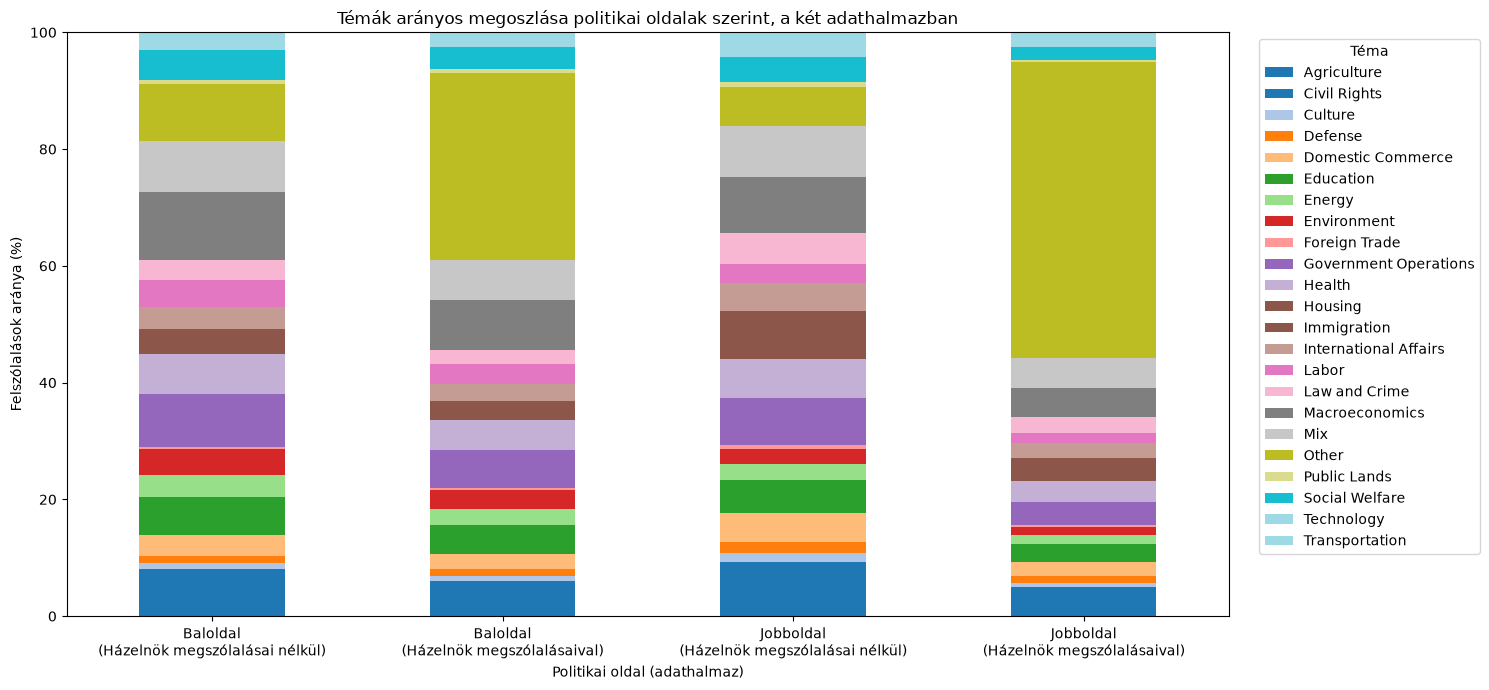

Makroszintű témaarányok (%):


tema,Agriculture,Civil Rights,Culture,Defense,Domestic Commerce,Education,Energy,Environment,Foreign Trade,Government Operations,...,International Affairs,Labor,Law and Crime,Macroeconomics,Mix,Other,Public Lands,Social Welfare,Technology,Transportation
Baloldal\n(Házelnök megszólalásai nélkül),3.54,4.47,1.03,1.30,3.55,6.57,3.68,4.46,0.44,8.95,...,3.73,4.66,3.36,11.68,8.67,9.71,0.74,5.10,0.82,2.28
Baloldal\n(Házelnök megszólalásaival),2.86,3.24,0.81,1.10,2.71,4.90,2.71,3.34,0.33,6.53,...,2.83,3.41,2.51,8.59,6.75,32.15,0.54,3.77,0.66,1.91
Jobboldal\n(Házelnök megszólalásai nélkül),4.30,5.03,1.48,1.95,4.86,5.62,2.79,2.63,0.57,8.06,...,4.70,3.31,5.38,9.54,8.72,6.72,0.81,4.20,1.09,3.21
Jobboldal\n(Házelnök megszólalásaival),2.56,2.40,0.79,1.13,2.47,2.93,1.54,1.40,0.31,4.05,...,2.61,1.71,2.70,4.97,5.15,50.67,0.40,2.25,0.65,1.81


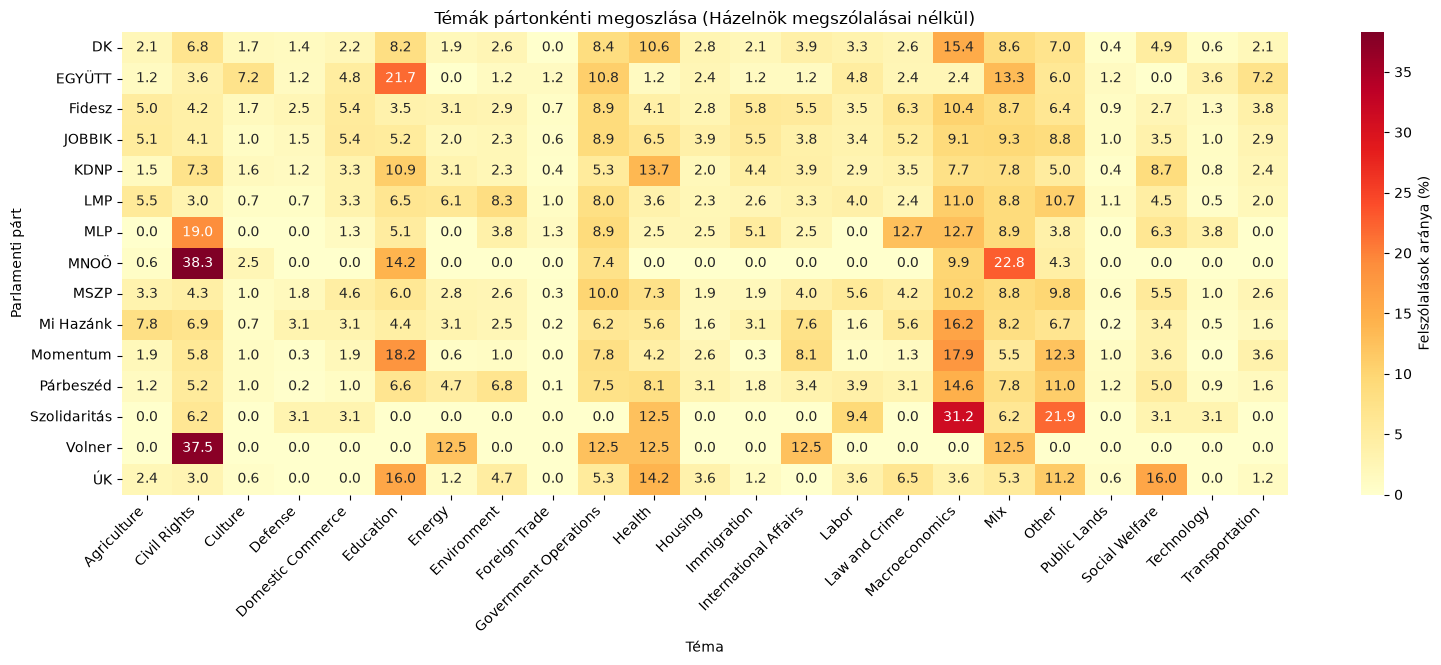

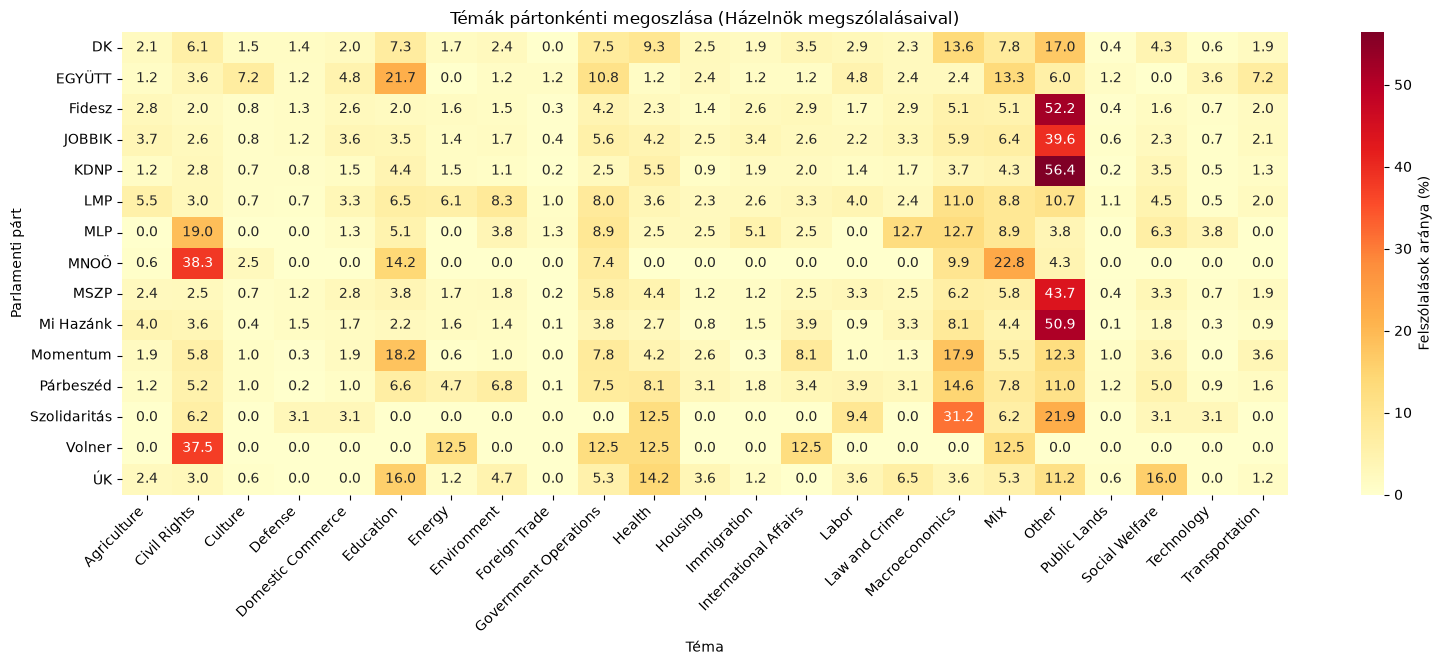

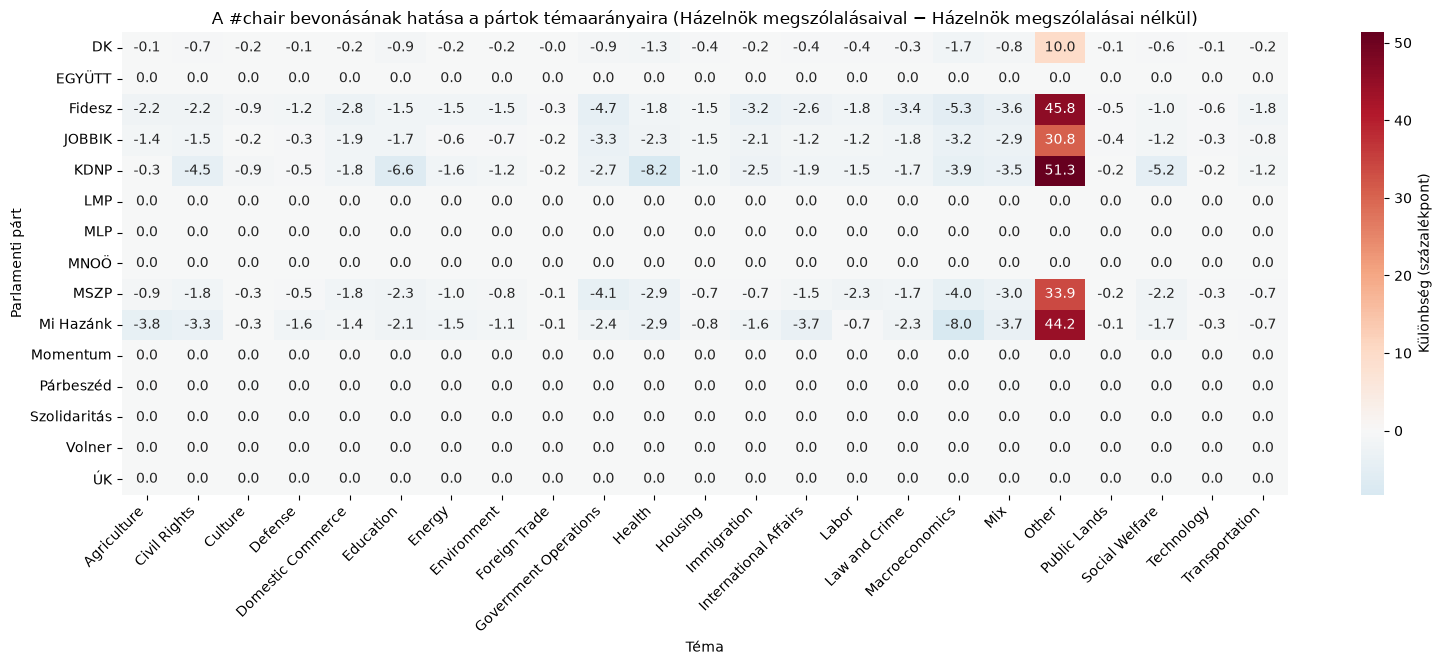

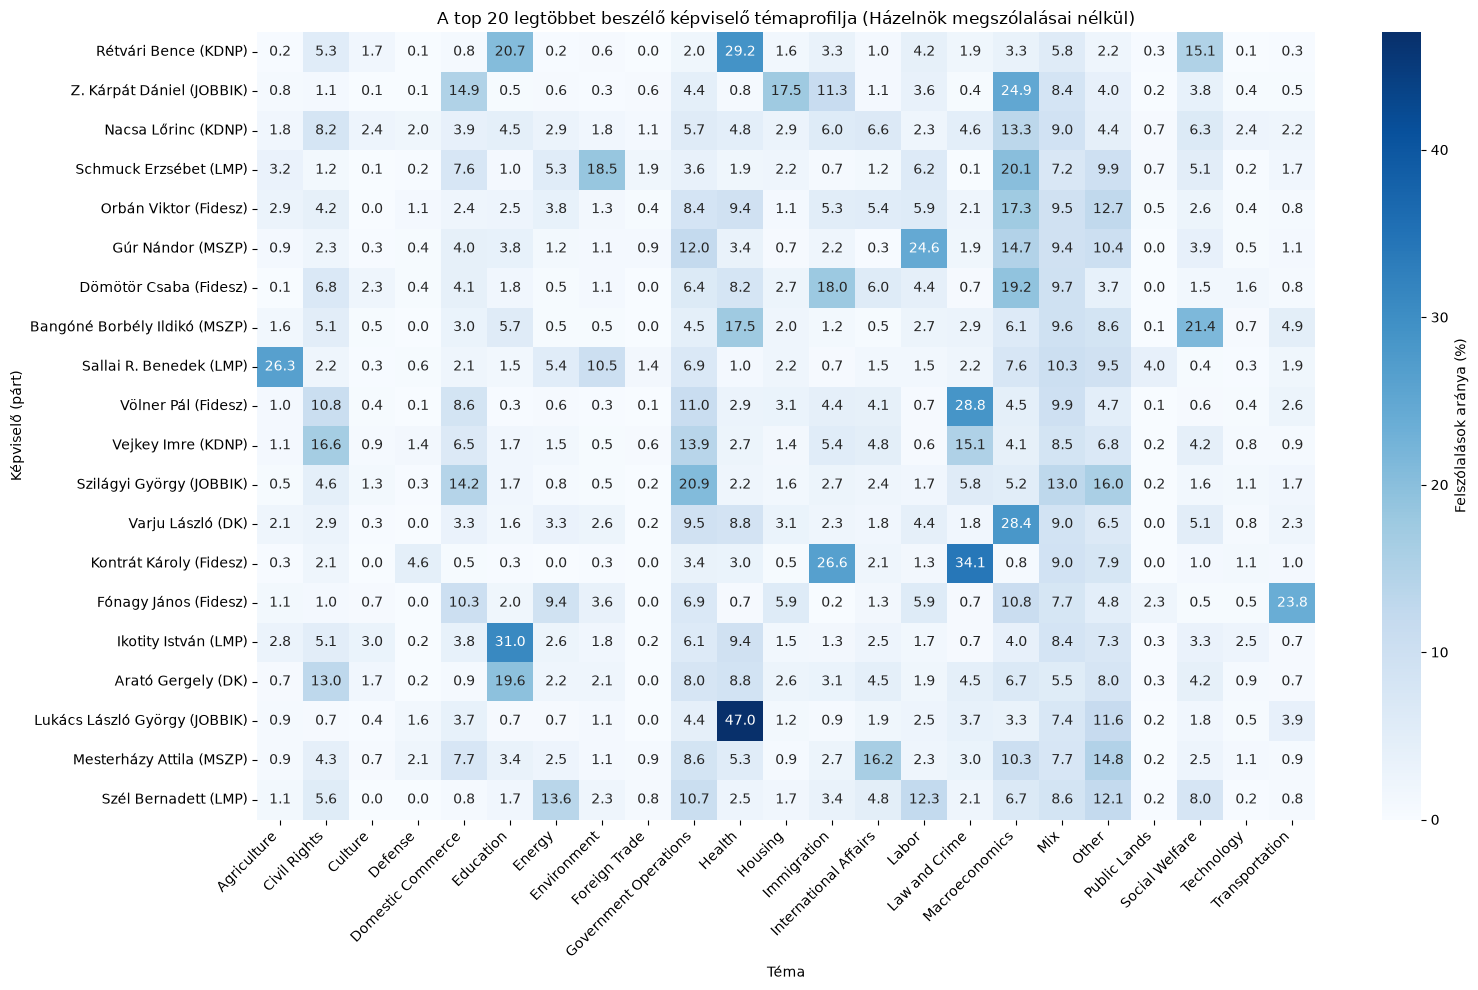

Top 20 képviselő a témával rendelkező felszólalások alapján (Házelnök megszólalásai nélkül):


,label,felszolalasok
0,Rétvári Bence (KDNP),2657
1,Z. Kárpát Dániel (JOBBIK),1306
2,Nacsa Lőrinc (KDNP),820
3,Schmuck Erzsébet (LMP),807
4,Orbán Viktor (Fidesz),758
5,Gúr Nándor (MSZP),741
6,Dömötör Csaba (Fidesz),734
7,Bangóné Borbély Ildikó (MSZP),732
8,Sallai R. Benedek (LMP),727
9,Völner Pál (Fidesz),688


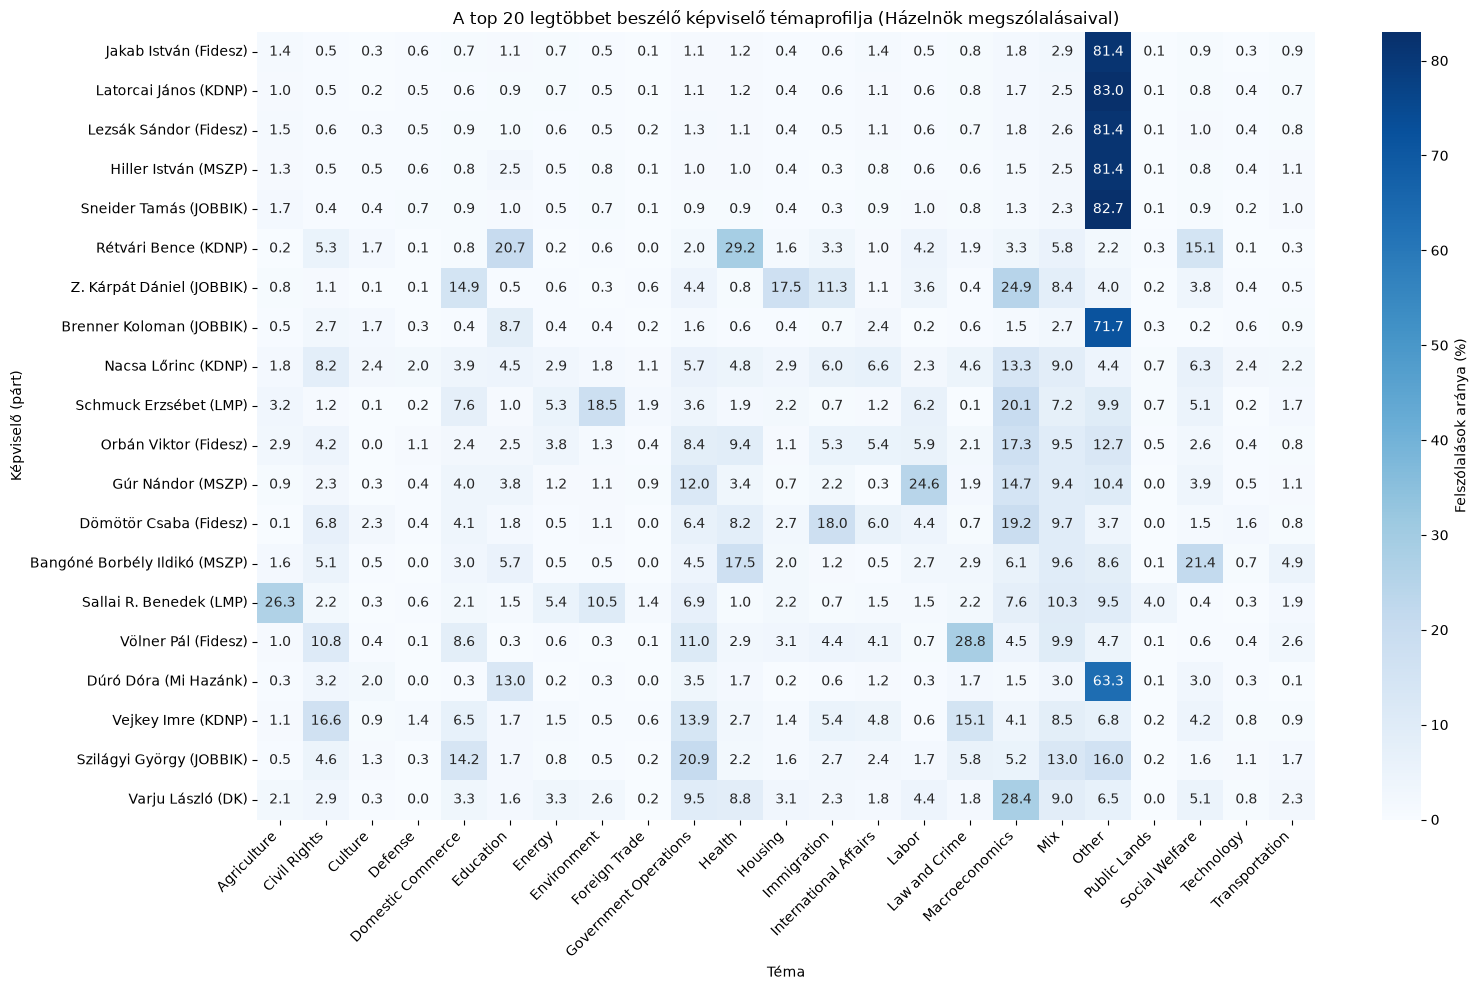

Top 20 képviselő a témával rendelkező felszólalások alapján (Házelnök megszólalásaival):


,label,felszolalasok
0,Jakab István (Fidesz),14713
1,Latorcai János (KDNP),13957
2,Lezsák Sándor (Fidesz),12305
3,Hiller István (MSZP),7217
4,Sneider Tamás (JOBBIK),5570
5,Rétvári Bence (KDNP),2657
6,Z. Kárpát Dániel (JOBBIK),1306
7,Brenner Koloman (JOBBIK),953
8,Nacsa Lőrinc (KDNP),820
9,Schmuck Erzsébet (LMP),807


In [ ]:
# TÉMAELEMZÉS: minden felszólalásnak van témacímkéje
# A témák kódjai és olvasható nevei
topic_names = {}
for category in (
    ET.parse(xml_dir / "ParlaMint-taxonomy-topic.xml")
    .getroot()
    .findall("tei:category", NS)
):
    key = category.get(XML_ID)
    topic_names[key] = category.findtext(
        "tei:catDesc/tei:term", default=key, namespaces=NS
    )

# Két adathalmaz: a teljes (#chair-rel) és a szűrt (#chair nélkül) -> csak a témával rendelkező felszólalásokkal
topic_df_teljes = (
    adatkeret_teljes.dropna(subset=["téma_azonosító"])
    .assign(
        tema=lambda t: t["téma_azonosító"].map(topic_names).fillna(t["téma_azonosító"])
    )
    .reset_index(drop=True)
)
if topic_df_teljes.empty:
    raise ValueError(
        "Nem sikerült témával és pártaffiliációval rendelkező felszólalást találni."
    )
topic_df = topic_df_teljes[
    ~topic_df_teljes["szerep"].isin(KIZART_SZEREPEK)
].reset_index(drop=True)
TEMA_DATASETEK = {CIMKE_SZURT: topic_df, CIMKE_TELJES: topic_df_teljes}
topic_order = sorted(topic_df_teljes["tema"].unique())
for cimke, adat in TEMA_DATASETEK.items():
    print(
        f"Témával és pártaffiliációval rendelkező felszólalások ({cimke}): {len(adat):,}".replace(
            ",", " "
        )
    )


# Megmutatja, hogy egy csoport (oldal vagy párt) felszólalásainak hány százaléka tartozik az egyes témákhoz.
def tema_aranyok(adat, csoport):
    return (
        pd.crosstab(adat[csoport], adat["tema"], normalize="index").reindex(
            columns=topic_order, fill_value=0
        )
        * 100
    )


# --------------------ÁBRÁK---------------------------------
# 1. A két politikai oldal témaarányai mindkét adathalmazban.
macro_tablak = {
    cimke: tema_aranyok(adat, "politikai_pólus").reindex(POLUSOK, fill_value=0)
    for cimke, adat in TEMA_DATASETEK.items()
}
macro_table = pd.concat(
    [
        tabla.set_axis([f"{oldal}\n({cimke})" for oldal in tabla.index])
        for cimke, tabla in macro_tablak.items()
    ]
).sort_index()
axis = macro_table.plot(kind="bar", stacked=True, figsize=(15, 7), colormap="tab20")
axis.set_title(
    "Témák arányos megoszlása politikai oldalak szerint, a két adathalmazban"
)
axis.set_xlabel("Politikai oldal (adathalmaz)")
axis.set_ylabel("Felszólalások aránya (%)")
axis.set_ylim(0, 100)
axis.legend(title="Téma", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Makroszintű témaarányok (%):")
display(macro_table.round(2))

# 2) Pártszint: hőtérkép adathalmazonként, majd a különbség (százalékpont)
party_tablak = {
    cimke: tema_aranyok(adat, "párt") for cimke, adat in TEMA_DATASETEK.items()
}
for cimke, party_table in party_tablak.items():
    plt.figure(figsize=(16, max(6, len(party_table) * 0.45)))
    sns.heatmap(
        party_table,
        annot=True,
        fmt=".1f",
        cmap="YlOrRd",
        cbar_kws={"label": "Felszólalások aránya (%)"},
    )
    plt.title(f"Témák pártonkénti megoszlása ({cimke})")
    plt.xlabel("Téma")
    plt.ylabel("Parlamenti párt")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# A két hőtérkép különbsége százalékpontban: pirossal, ahol a #chair bevonása növeli a téma arányát, kékkel, ahol csökkenti.
party_kulonbseg = party_tablak[CIMKE_TELJES].sub(
    party_tablak[CIMKE_SZURT], fill_value=0
)
plt.figure(figsize=(16, max(6, len(party_kulonbseg) * 0.45)))
sns.heatmap(
    party_kulonbseg,
    annot=True,
    fmt=".1f",
    cmap="RdBu_r",
    center=0,
    cbar_kws={"label": "Különbség (százalékpont)"},
)
plt.title(
    f"A #chair bevonásának hatása a pártok témaarányaira ({CIMKE_TELJES} − {CIMKE_SZURT})"
)
plt.xlabel("Téma")
plt.ylabel("Parlamenti párt")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3) A top 20 legtöbbet beszélő képviselő témaprofilja, adathalmazonként
for cimke, adat in TEMA_DATASETEK.items():
    # A 20 legtöbbet felszólaló képviselő.
    speaker_counts = (
        adat.groupby(["beszélő_azonosító", "párt"])
        .size()
        .sort_values(ascending=False)
        .head(20)
        .reset_index(name="felszolalasok")
    )
    speaker_counts["label"] = (
        speaker_counts["beszélő_azonosító"]
        .map(person_names)
        .fillna(speaker_counts["beszélő_azonosító"])
        + " ("
        + speaker_counts["párt"]
        + ")"
    )
    speaker_topic = adat.merge(
        speaker_counts[["beszélő_azonosító", "label"]],
        on="beszélő_azonosító",
        how="inner",
    )
    # Minden képviselőnél a témák százalékos megoszlása.
    speaker_table = (
        pd.crosstab(speaker_topic["label"], speaker_topic["tema"], normalize="index")
        .reindex(columns=topic_order, fill_value=0)
        .reindex(speaker_counts["label"])
        * 100
    )
    plt.figure(figsize=(16, 10))
    sns.heatmap(
        speaker_table,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        cbar_kws={"label": "Felszólalások aránya (%)"},
    )
    plt.title(f"A top 20 legtöbbet beszélő képviselő témaprofilja ({cimke})")
    plt.xlabel("Téma")
    plt.ylabel("Képviselő (párt)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    print(f"Top 20 képviselő a témával rendelkező felszólalások alapján ({cimke}):")
    display(speaker_counts[["label", "felszolalasok"]])